<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/RBM_AnnealingIntrusionDetection_Dixit2021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Annealing-trained restricted Boltzmann machine for intrusion detection: Dixit et al. (2021) step by step

This notebook re-implements, runs and checks the method of

> Vivek Dixit, Raja Selvarajan, Tamer Aldwairi, Yaroslav Koshka, Mark A. Novotny, Travis S. Humble, Muhammad A. Alam and Sabre Kais,
> "Training a quantum annealing based restricted Boltzmann machine on cybersecurity data",
> *IEEE Transactions on Emerging Topics in Computational Intelligence*, 2021 (arXiv:2011.13996).

**What the notebook does.** It downloads the real **ISCX IDS 2012** network flows (a public Hugging Face mirror of the Canadian Institute for Cybersecurity data), turns every flow into a **62-bit binary vector** with a supervised (Fayyad-Irani / MDL) discretisation, appends the paper's **2 target bits** (`01` benign, `10` attack) to get a 64-bit record, and trains a **64 visible x 64 hidden restricted Boltzmann machine (RBM)** two ways: with **contrastive divergence (CD-1)** and with a **quantum-annealing-style sampler** for the model term of the gradient. It then repeats the paper's three experiments: the imbalanced baseline, **Scheme 1** (five balanced sub-datasets and a majority vote, Table I) and **Scheme 2** (synthetic attack records generated by the RBM to balance the training data, Tables II and III).

**Important honest note.** The authors sampled with a physical D-Wave 2000Q annealer. No annealer is available here, so the annealing step is replaced by a **simulated annealer** (annealed block-Gibbs sampling on the same Ising Hamiltonian, cross-checked against D-Wave's own `dwave-samplers` simulated annealer). This is a classical stand-in for the hardware: it can say whether the *algorithm* works with a "cold, imperfect" sampler, it cannot say anything about quantum speed-ups or quantum effects. See the table in "The paper in one page" for every other difference.

**How to run it.** Open in Google Colab (CPU runtime is enough, everything is plain NumPy), then *Runtime -> Run all*. `FAST_MODE = False` (the setting of this executed copy: three seeds, 60 epochs, 10,000 synthetic records per generator in Table II, the paper's number) took about 62 minutes on a shared laptop CPU; `FAST_MODE = True` (one seed, 40 epochs, 4,000 synthetic records) is the class-demo setting and took about 18 minutes on the same machine. Set it in the configuration cell before running. The first run streams the public 1 GB ISCX archive once (only the six CSV files are parsed, about 5-10 minutes) and caches a small file; later runs reuse the cache.

**What you get at the end.** Every number of the paper's Tables I, II and III next to the number measured here, a verdict per claim ("reproduced" within 2 percentage points / 0.02, "not reached", "exceeded" or "cannot be checked"), re-drawn figures, a classical baseline (logistic regression, random forest) on the very same 62 bits, and a critical reading of the paper.

## The paper in one page

**Problem.** Network intrusion data are imbalanced (attack flows are rare) and classifiers trained on them miss attacks. The paper asks (i) whether an RBM can be trained with samples from a quantum annealer on a cybersecurity data set, and (ii) whether an RBM can generate synthetic attack records to balance the training data.

**Decision.** Binary: benign versus attack. An RBM with 64 visible units holds 62 data bits plus 2 target bits; to classify, the 62 data bits are applied and the two target bits are read back after one reconstruction (`01` benign, `10` attack, `00`/`11` indeterminate and counted as errors).

**Method.**
- *RBM* with energy $E(v,h)=-b^\top v-c^\top h-h^\top W v$ (Eq. 2), $P(h_j{=}1|v)=\sigma(c_j+(v^\top W)_j)$ (Eq. 10), $P(v_i{=}1|h)=\sigma(b_i+(h^\top W)_i)$ (Eq. 11). Gradient (Eqs. 16-18): data term minus model term.
- *CD-1* (Algorithm 1): $H=\sigma(c+VW)$, $V'=\sigma(b+HW^\top)$, $H'=\sigma(c+V'W)$, updates $\epsilon(V^\top H-V'^\top H')/m$ (and the analogous bias updates).
- *Quantum annealing* (Algorithm 2): the data term is the same, the model term $(V',H')$ comes from samples of the annealer programmed with the Ising form of the RBM (Eqs. 20-23: $W'=W/4$, $b'=b/2+\sum_j W_{ij}/4$), with the energy scaled by a hyper-parameter $S$ so that $S\,kT\approx 1$; 20 microsecond anneals; a fully connected 64 x 64 RBM embedded on the Chimera graph with chains of 16 qubits.
- *Scheme 1*: undersample the benign class: the training set (18,000 benign / 3,450 attack) becomes five balanced sub-datasets A-E, five RBMs are trained, **majority vote** on the test set (7,230 benign / 1,467 attack).
- *Scheme 2*: train an RBM, generate synthetic records (CD: 50 Gibbs cycles from a random 64-bit vector; QA: 10,000 annealer samples), add 14,550 synthetic attack records to the 3,450 real ones, train six classifiers (RBM, neural network (62-8-8-8-2, relu, adam), 3-NN, SVC, decision tree (depth 5), Gaussian naive Bayes).
- *Data.* ISCX IDS 2012, seven days of traffic with benign and attack flows. Categorical to numeric, dimensionality reduction and **supervised discretisation in Weka** to 62 binary columns; 137,584 binary instances of which only 30,147 are unique (25,230 benign, 4,917 attack).

**Claims checked here (paper values).**
- Imbalanced CD-1 RBM: attack accuracy 42 %, benign accuracy 97 % (500 + 500 test records).
- Table I (Scheme 1), CD-1: average total accuracy 90.24 %, majority vote 95.68 % (benign 96.17 %, attack 93.25 %); QA: average 74.14 %, majority vote 80.04 % (benign 74.46 %, attack 85.62 %).
- Table II: RBMs trained on synthetic data: average total accuracy 71.21 % (CD-generated) and 70.00 % (QA-generated).
- Table III (a balanced 500 + 500 test set, see the note in section 6): balanced training improves every classifier; e.g. NN and KNN reach 93 %, RBM 85 % (CD-bal) / 82 % (QA-bal) against 66-70 % and 68 % on the imbalanced data.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | ISCX IDS 2012 from the CIC website, 137,584 binarised instances (30,147 unique) | Same data set: Hugging Face mirror `bencorn/ISCX-IDS-2012` (the CIC CSVs), all six CSV days of the archive (Sat 12 to Thu 17 June 2010; the CIC page lists a seventh day, Fri 11 June, which is not in the mirror). Flow counts are printed in the notebook. |
| Features | "categorical to numeric, dimensionality reduction, binarisation" (unspecified columns) | 5 numeric flow statistics (bytes and packets per direction, duration), `appName`, `direction`, `protocolName`, source and destination TCP flags; **no IPs, ports or timestamps** (CLAUDE.md rule). `# CHOICE:` |
| Binarisation | Weka supervised discretisation, fitted on the whole data | Own implementation of the Fayyad-Irani MDL discretiser (thermometer bits), plus one-hot bits for categorical values; **fitted on the training flows only**, then mutual-information selection with a redundancy filter to exactly **62 bits** (also train-only). `# CHOICE:` |
| Target bits | `01` benign, `10` attack, `00`/`11` indeterminate (wrong) | Same |
| Unique records | Duplicates removed, then 70/30 split | Raw flows de-duplicated, stratified 70/30 split of flows, discretiser fitted on the train part, identical 64-bit records removed inside each part, and test records whose 62 bits also occur in the training set are dropped (so train and test share no record). `# CHOICE:` |
| RBM size | 64 visible x 64 hidden | Same |
| RBM hyper-parameters | learning rate, mini-batch, epochs, weight initialisation not given | normal(0, 0.01) init (as Algorithm 1 says "small normally distributed"), mini-batch and learning rate set in the configuration cell, epochs from the configuration; chosen on a validation split cut from the training data. `# CHOICE:` |
| Classification with the RBM | apply 62 bits, read the 2 target bits after reconstruction | Same (target bits start at 0, one up-down pass with probabilities, threshold 0.5). A free-energy read-out is reported as an extra. `# CHOICE:` |
| Annealer | D-Wave 2000Q, 20 microsecond anneals, minor-embedded RBM (chains of 16 qubits), scaling $S$ chosen by manual search | **Simulated annealer** (annealed block-Gibbs on the Ising model, 128 spins), scaling $S$ chosen on a validation split; cross-checked with `dwave-samplers` `SimulatedAnnealingSampler`. No quantum effects, no chains, no hardware noise. `# CHOICE:` |
| Synthetic data | CD: 50 Gibbs cycles from a random 64-bit vector; QA: 10,000 anneals | Same procedure, but many more draws are generated because only samples whose target bits read `10` are kept as synthetic attack records. |
| Classifiers | scikit-learn NN (62-8-8-8-2), 3-NN, SVC, DT (max depth 5), GaussianNB, RBM | Same scikit-learn settings; the 2 target bits are used as a single class label. Additional baselines: logistic regression and random forest. |
| Repeats | one run | `SEEDS` independent runs (data split fixed, RBM seeds vary) with mean +- std in the comparison. |
| Test set | 8,697 records (7,230 / 1,467) and a 500 + 500 set | Whatever the unique-record protocol leaves (printed; far fewer records, 63 of them attacks), and a random subset (500 benign + all attack records) for the first claim. `# CHOICE:` |
| Table III evaluation | not stated; the numbers (e.g. NN imbal: recalls 0.32 and 1.00, accuracy 66 %) are those of a balanced test set | Balanced accuracy and class-reweighted precision / recall / F1 (the expected values on a balanced test set); the natural-test accuracy is shown as an extra column. `# CHOICE:` |
| Number of synthetic records | 14,550 attack records added to 3,450 (equal classes) | As many as needed to equalise the classes of the fitting set (draws are repeated until enough records read out as attack, capped by `N_GEN_MAX`). |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and requests.
# Only the optional cross-check against D-Wave's own simulated annealer needs an extra package.
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")       # the RBM works on tiny matrices (50 x 64 @ 64 x 64): one BLAS thread is fastest and avoids oversubscription
import importlib.util
def _has(mod):
    try:
        return importlib.util.find_spec(mod) is not None
    except ModuleNotFoundError:
        return False
IN_COLAB = _has("google.colab")
if IN_COLAB or not _has("dwave.samplers") or not _has("huggingface_hub"):
    %pip install -q "dwave-samplers==1.8.0" "dimod==0.12.22" huggingface_hub
    print("packages installed (a session restart is normally not needed).")
else:
    print("packages already present; skipping pip install.")

packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo (a few minutes). False: more epochs and seeds (see the budgets below).
SEED      = 42              # master seed
DATA_DIR  = "iscx2012_cache" # downloaded/derived files are cached here (about 5 MB)
IBM_TOKEN = ""              # unused: no gate-based quantum circuit in this paper
DWAVE_TOKEN = ""            # unused: no D-Wave hardware access; the annealer is simulated
DATA_SOURCE = "hf"          # "hf": stream the public Hugging Face mirror; "local": read LOCAL_ISCX_TAR
LOCAL_ISCX_TAR = ""         # optional path to iscxids2012-master.tar.gz (or a folder with the CSV files) if you have it

N_BITS, N_LABEL = 62, 2     # paper: 62 binary features + 2 target bits = 64 visible units
N_VIS, N_HID    = N_BITS + N_LABEL, 64
TEST_FRACTION   = 0.30      # paper: about 70 % : 30 %
BENIGN_TRAIN_CAP, BENIGN_TEST_CAP = 18000, 7230     # paper: 18,000 benign training records, 7,230 benign test records
BAL_TEST = 500              # paper: 500 attack + 500 benign for the imbalanced-RBM result
MAX_CORR = 0.95             # CHOICE: redundancy filter when picking the 62 bits
CUTS_PER_FEATURE = 12       # CHOICE: at most this many MDL cut points kept per numeric feature (evenly thinned)

# RBM training (the paper gives none of these)
LR, BATCH = 0.05, 50                    # CHOICE: learning rate and mini-batch size
ANNEAL_SWEEPS = 20                      # CHOICE: sweeps of the simulated anneal (one sweep = h|v then v|h)
BETA_START = 0.1                        # CHOICE: start of the geometric inverse-temperature ramp (end = S)
S_GRID = [0.5, 0.75, 1.0, 1.5, 2.0]     # CHOICE: grid for the manual search of the energy scale S

if FAST_MODE:
    EPOCHS_CD, EPOCHS_QA = 40, 40       # CHOICE: epochs (validated on the training data: more epochs over-fit the small sub-datasets)
    SEEDS = [SEED]
    N_GEN_MAX = 400_000                 # cap on synthetic draws per generator (only about 2-3 % of the draws read out as attack)
    N_SYN_T2 = 4000                     # synthetic records per generator in Table II (paper: 10,000)
    S_SEARCH_EPOCHS = 25
else:
    EPOCHS_CD, EPOCHS_QA = 60, 60
    SEEDS = [SEED, SEED + 1, SEED + 2]
    N_GEN_MAX = 800_000
    N_SYN_T2 = 10000
    S_SEARCH_EPOCHS = 40
print("FAST_MODE =", FAST_MODE, "| epochs", EPOCHS_CD, EPOCHS_QA, "| seeds", SEEDS)

FAST_MODE = False | epochs 60 60 | seeds [42, 43, 44]


In [3]:
import os, io, time, math, tarfile, warnings, importlib.metadata as im
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

import requests

# Hugging Face token: the ISCX mirror is public, so none is needed; a token is only read if one is set (Colab Secrets or environment).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (optional)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
try:
    print("dwave-samplers", im.version("dwave-samplers"), "| dimod", im.version("dimod"))
except Exception as e:
    print("dwave-samplers not installed (only the optional cross-check is skipped):", e)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
dwave-samplers 1.8.0 | dimod 0.12.22


## 1. The ISCX IDS 2012 flows

ISCX IDS 2012 (Shiravi, Shiravi, Tavallaee and Ghorbani, *Computers & Security* 2012) is a labelled capture of seven days of traffic in a synthetic enterprise testbed. Each row is one **bidirectional flow** described by the application name detected by deep-packet inspection, bytes and packets in each direction, TCP flags, protocol, ports, IP addresses and start/stop times; `Label` says `Normal` or `Attack`. The attacks of the data set are an infiltration scenario, an HTTP denial of service, a distributed denial of service with an IRC botnet and an SSH brute force, scheduled on different days.

The public Hugging Face mirror `bencorn/ISCX-IDS-2012` is a single 1 GB archive. The cell below **streams** it and reads the six CSV files of the days Sat 12 to Thu 17 June 2010 (the archive stops reading as soon as all six have been parsed), keeps 12 columns (the raw payload text, ports and IP addresses are never loaded), drops repeated flows and caches the result (a few MB). The archive does not give attack families, only `Normal` / `Attack`; here the **capture day** is used as the family label of attack flows, because the dataset documentation assigns different attack scenarios to different days.

In [4]:
USE_COLS = ["appName", "totalSourceBytes", "totalDestinationBytes", "totalDestinationPackets", "totalSourcePackets",
            "direction", "sourceTCPFlagsDescription", "destinationTCPFlagsDescription", "protocolName",
            "startDateTime", "stopDateTime", "Label"]
DAY_FILES = {"TestbedSatJun12Flows.csv": "Sat 12 Jun", "TestbedSunJun13Flows.csv": "Sun 13 Jun",   # all six CSV days of the mirror
             "TestbedMonJun14Flows.csv": "Mon 14 Jun", "TestbedTueJun15Flows.csv": "Tue 15 Jun",
             "TestbedWedJun16Flows.csv": "Wed 16 Jun", "TestbedThuJun17Flows.csv": "Thu 17 Jun"}
FLOW_CACHE = os.path.join(DATA_DIR, "iscx2012_flows_reduced.csv.gz")

class _Raw(io.RawIOBase):                      # lets pandas read a member of a streamed (non seekable) tar archive
    def __init__(self, f): self.f = f
    def readable(self): return True
    def readinto(self, b):
        d = self.f.read(len(b)); b[:len(d)] = d; return len(d)

def _read_day(fobj, day):
    parts = []
    for ch in pd.read_csv(io.BufferedReader(_Raw(fobj), 1 << 20), usecols=USE_COLS, chunksize=200_000, low_memory=False):
        ch["day"] = day
        parts.append(ch.drop_duplicates())
    return pd.concat(parts, ignore_index=True)

def load_flows():
    if os.path.exists(FLOW_CACHE):
        print("using cache", FLOW_CACHE)
        return pd.read_csv(FLOW_CACHE)
    t0 = time.time(); got = {}
    if DATA_SOURCE == "local" and LOCAL_ISCX_TAR and os.path.isdir(LOCAL_ISCX_TAR):
        for fn, day in DAY_FILES.items():
            with open(os.path.join(LOCAL_ISCX_TAR, fn), "rb") as f:
                got[day] = _read_day(f, day)
    else:
        from huggingface_hub import hf_hub_url
        url = hf_hub_url("bencorn/ISCX-IDS-2012", "iscxids2012-master.tar.gz", repo_type="dataset")
        hdr = {"Authorization": "Bearer " + HF_TOKEN} if HF_TOKEN else {}
        for attempt in range(12):                      # a dropped connection restarts the stream; days already parsed are skipped
            if len(got) == len(DAY_FILES): break
            try:
                if DATA_SOURCE == "local" and LOCAL_ISCX_TAR: raw = open(LOCAL_ISCX_TAR, "rb")
                else:
                    resp = requests.get(url, headers=hdr, stream=True, timeout=120); resp.raise_for_status(); raw = resp.raw
                tf = tarfile.open(fileobj=raw, mode="r|gz")
                for m in tf:
                    fn = os.path.basename(m.name)
                    if m.name.startswith("iscxids2012-master/data/CSV/") and fn in DAY_FILES and DAY_FILES[fn] not in got:
                        got[DAY_FILES[fn]] = _read_day(tf.extractfile(m), DAY_FILES[fn])
                        print(f"  read {fn}: {len(got[DAY_FILES[fn]]):,} distinct flows ({time.time()-t0:.0f} s)", flush=True)
                        if len(got) == len(DAY_FILES): break
            except Exception as e:
                print(f"  connection problem ({type(e).__name__}); retrying, {len(got)}/{len(DAY_FILES)} days read", flush=True)
    if len(got) < len(DAY_FILES): raise RuntimeError("could not read all days; set DATA_SOURCE='local' with LOCAL_ISCX_TAR")
    df = pd.concat(got.values(), ignore_index=True).drop_duplicates().reset_index(drop=True)
    df.to_csv(FLOW_CACHE, index=False)
    print(f"cached {len(df):,} flows in {FLOW_CACHE} ({os.path.getsize(FLOW_CACHE)/1e6:.1f} MB)")
    return df
flows = load_flows()
print("flows:", flows.shape)
display(flows.head(3))

using cache iscx2012_cache\iscx2012_flows_reduced.csv.gz


flows: (1335356, 13)


,appName,totalSourceBytes,totalDestinationBytes,totalDestinationPackets,totalSourcePackets,direction,sourceTCPFlagsDescription,destinationTCPFlagsDescription,protocolName,startDateTime,stopDateTime,Label,day
0,Unknown_UDP,16076,0,0,178,L2R,NaN,NaN,udp_ip,6/13/2010 23:57,6/14/2010 0:11,Normal,Mon 14 Jun
1,HTTPImageTransfer,384,0,0,6,L2R,"F,A",NaN,tcp_ip,6/13/2010 23:58,6/14/2010 0:01,Normal,Mon 14 Jun
2,DNS,171,642,4,2,L2L,NaN,NaN,udp_ip,6/13/2010 23:58,6/13/2010 23:59,Normal,Mon 14 Jun


## 2. Cleaning and labels

- Duration is computed from the two time stamps (the time stamps themselves are then dropped; so are IP addresses and ports, which are identifiers).
- Missing TCP-flag text means "not a TCP flow" (UDP, ICMP, ...), so it becomes the empty string.
- The binary label is `Attack` = 1. The **family** is `benign` or `attack (<capture day>)`.
- Exact duplicate flows were already removed while reading.

In [5]:
flows["dur"] = (pd.to_datetime(flows["stopDateTime"]) - pd.to_datetime(flows["startDateTime"])).dt.total_seconds()
flows["sourceTCPFlagsDescription"] = flows["sourceTCPFlagsDescription"].fillna("")
flows["destinationTCPFlagsDescription"] = flows["destinationTCPFlagsDescription"].fillna("")
flows["y"] = (flows["Label"] == "Attack").astype(int)
flows["family"] = np.where(flows["y"] == 1, "attack (" + flows["day"] + ")", "benign")
flows = flows.drop(columns=["startDateTime", "stopDateTime"]).drop_duplicates().reset_index(drop=True)
NUM_COLS = ["totalSourceBytes", "totalDestinationBytes", "totalSourcePackets", "totalDestinationPackets", "dur"]
CAT_COLS = ["appName", "direction", "protocolName"]
FLAG_COLS = ["sourceTCPFlagsDescription", "destinationTCPFlagsDescription"]
print("flows after cleaning:", flows.shape)
display(pd.crosstab(flows["day"], flows["Label"], margins=True))

flows after cleaning: (627492, 14)


Label,Attack,Normal,All
day,,,
Mon 14 Jun,350,58786,59136
Sat 12 Jun,248,48555,48803
Sun 13 Jun,655,43747,44402
Thu 17 Jun,273,135463,135736
Tue 15 Jun,5178,164128,169306
Wed 16 Jun,5,170104,170109
All,6709,620783,627492


## 3. Binarisation to 62 bits (supervised discretisation, fitted on the training flows only)

The paper discretises with Weka's *supervised* filter, which is the **Fayyad-Irani entropy / minimum-description-length (MDL)** method: for a numeric column it recursively picks the cut point with the largest information gain about the class and keeps it only if the gain exceeds the MDL cost. Each cut point `t` becomes one binary column "value > t" (a *thermometer* code). Categorical values become one-hot columns, and the TCP-flag text becomes one column per flag letter.

The candidate columns are then reduced to **exactly 62 bits** (the paper's number) by ranking them by mutual information with the label and skipping any column whose absolute correlation with an already selected column is above `MAX_CORR`. Every one of these steps (cut points, categories, mutual information, selection) is **fitted on the training flows only**, then applied unchanged to the test flows.

In [6]:
# ---------- Fayyad-Irani MDL discretiser (own implementation) ----------
def _entropy(c):
    n = c.sum(-1, keepdims=True)
    p = np.where(n > 0, c / np.maximum(n, 1), 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        return -(np.where(p > 0, p * np.log2(p), 0)).sum(-1)

def mdlp_cuts(x, y):
    """Entropy/MDL cut points (Fayyad & Irani 1993) of a numeric column x for binary labels y."""
    u, inv = np.unique(x, return_inverse=True)
    cnt = np.zeros((len(u), 2)); np.add.at(cnt, (inv, y), 1)
    cuts = []
    def rec(lo, hi):
        seg = cnt[lo:hi]
        if len(seg) < 2: return
        tot = seg.sum(0); N = tot.sum(); Es = _entropy(tot)
        cl = np.cumsum(seg, 0)[:-1]; cr = tot - cl
        E = (cl.sum(1) * _entropy(cl) + cr.sum(1) * _entropy(cr)) / N
        i = int(np.argmin(E)); gain = Es - E[i]
        k = (tot > 0).sum(); k1 = (cl[i] > 0).sum(); k2 = (cr[i] > 0).sum()
        delta = np.log2(3 ** k - 2) - (k * Es - k1 * _entropy(cl[i]) - k2 * _entropy(cr[i]))
        if gain > (np.log2(N - 1) + delta) / N:
            cuts.append((u[lo + i] + u[lo + i + 1]) / 2)
            rec(lo, lo + i + 1); rec(lo + i + 1, hi)
    rec(0, len(u))
    return sorted(cuts)

def thin(cuts, k):                       # CHOICE: keep at most k evenly spread cut points per column
    if len(cuts) <= k: return list(cuts)
    return [cuts[i] for i in np.unique(np.linspace(0, len(cuts) - 1, k).round().astype(int))]

def col_values(d, spec):
    kind, name, par = spec
    if kind == "num":  return (d[name].values > par)
    if kind == "cat":  return (d[name].values == par)
    if kind == "flag":
        m = {s: (par in s) for s in d[name].unique()}
        return d[name].map(m).values
    if kind == "noflag": return (d[name].values == "")

def col_label(spec):
    kind, name, par = spec
    short = {"sourceTCPFlagsDescription": "srcFlag", "destinationTCPFlagsDescription": "dstFlag"}.get(name, name)
    return f"{short}>{par:.4g}" if kind == "num" else (f"{short}={par}" if kind == "cat" else (f"{short}:{par}" if kind == "flag" else f"{short}:none"))

def binary_mi(X, y):
    """Mutual information (bits) between each binary column of X and the binary label y."""
    n = len(y); n1 = y.sum(); n0 = n - n1
    a = X.sum(0, dtype=np.float64); a1 = (X.T.astype(np.float32) @ y.astype(np.float32)).astype(np.float64); a0 = a - a1
    mi = np.zeros(X.shape[1])
    for nxy, nx, ny in [(a1, a, n1), (a0, a, n0), (n1 - a1, n - a, n1), (n0 - a0, n - a, n0)]:
        with np.errstate(divide="ignore", invalid="ignore"):
            mi += np.where(nxy > 0, nxy / n * np.log2(nxy * n / (nx * ny)), 0)
    return mi

def fit_binariser(d, y):
    """Fit cut points, categories and the 62-bit selection on the training flows d (labels y). Returns the list of 62 column specs."""
    specs = []
    for c in NUM_COLS:
        specs += [("num", c, t) for t in thin(mdlp_cuts(d[c].values.astype(float), y), CUTS_PER_FEATURE)]
    for c in CAT_COLS:
        specs += [("cat", c, v) for v in sorted(d[c].unique())]
    for c in FLAG_COLS:
        specs += [("flag", c, f) for f in "FSRPAU"] + [("noflag", c, None)]
    X = np.column_stack([col_values(d, s) for s in specs]).astype(np.uint8)
    keep = np.where((X.sum(0) >= 20) & (X.sum(0) <= len(X) - 20))[0]               # drop (almost) constant columns
    specs = [specs[i] for i in keep]; X = X[:, keep]
    mi = binary_mi(X, y)
    Xf = X.astype(np.float32); Xf -= Xf.mean(0); Xf /= (Xf.std(0) + 1e-9)
    C = np.abs(Xf.T @ Xf) / len(Xf)
    order = list(np.argsort(-mi)); sel = []
    for j in order:                                                                 # CHOICE: MI ranking with a redundancy filter
        if all(C[j, s] < MAX_CORR for s in sel): sel.append(j)
        if len(sel) == N_BITS: break
    for j in order:                                                                 # fill up if the filter left fewer than 62
        if len(sel) == N_BITS: break
        if j not in sel: sel.append(j)
    return [specs[j] for j in sel], mi[sel]

def apply_binariser(d, specs):
    return np.column_stack([col_values(d, s) for s in specs]).astype(np.uint8)

def pack_bits(B):                          # 62 bits -> one uint64 per record (used to find identical records)
    w = (np.uint64(1) << np.arange(B.shape[1], dtype=np.uint64))
    return (B.astype(np.uint64) * w).sum(1, dtype=np.uint64)

### Split, binarise, keep unique records

The split is made **on flows, before any fitting**, stratified by family so that every attack day appears in both parts. After binarising, identical records collapse (the paper reports 137,584 binarised instances but only 30,147 unique ones). The paper builds its train/test sets from unique records, so here too:
- inside the training part, identical (62 bits + label) records are kept once;
- inside the test part likewise, and every test record whose 62 bits also occur in the training part is removed.

In [7]:
t0 = time.time()
idx_tr, idx_te = train_test_split(np.arange(len(flows)), test_size=TEST_FRACTION, stratify=flows["family"], random_state=SEED)
d_tr, d_te = flows.iloc[idx_tr].reset_index(drop=True), flows.iloc[idx_te].reset_index(drop=True)
specs, mi_sel = fit_binariser(d_tr, d_tr["y"].values)               # fitted on training flows only
BIT_NAMES = [col_label(s) for s in specs]
B_tr, B_te = apply_binariser(d_tr, specs), apply_binariser(d_te, specs)
print(f"binariser fitted in {time.time()-t0:.0f} s; {len(specs)} bits; flows train/test = {len(d_tr):,}/{len(d_te):,}")
print("selected bits:", BIT_NAMES)

def unique_records(B, y, fam, exclude_codes=None):
    code_ = pack_bits(B)
    key = code_ * np.uint64(2) + y.astype(np.uint64)
    _, first = np.unique(key, return_index=True)
    first = np.sort(first)
    if exclude_codes is not None:
        first = first[~np.isin(code_[first], exclude_codes)]
    return B[first], y[first], fam[first], first

Btr_u, ytr_u, ftr_u, _ = unique_records(B_tr, d_tr["y"].values, d_tr["family"].values)
Bte_u, yte_u, fte_u, _ = unique_records(B_te, d_te["y"].values, d_te["family"].values, exclude_codes=pack_bits(Btr_u))
print(f"binarised flows: train {len(B_tr):,} -> unique records {len(Btr_u):,} (benign {int((ytr_u==0).sum()):,}, attack {int((ytr_u==1).sum()):,})")
print(f"                 test  {len(B_te):,} -> unique records not seen in training {len(Bte_u):,} (benign {int((yte_u==0).sum()):,}, attack {int((yte_u==1).sum()):,})")

binariser fitted in 18 s; 62 bits; flows train/test = 439,244/188,248
selected bits: ['direction=L2R', 'totalSourceBytes>7292', 'totalDestinationPackets>142.5', 'totalDestinationBytes>1.604e+05', 'totalDestinationBytes>1.188e+05', 'totalSourcePackets>55.5', 'totalDestinationPackets>80.5', 'totalSourcePackets>59.5', 'totalSourcePackets>46.5', 'totalDestinationPackets>168.5', 'appName=HTTPImageTransfer', 'totalSourceBytes>1466', 'totalSourceBytes>1604', 'appName=HTTPWeb', 'totalDestinationPackets>195.5', 'direction=R2L', 'totalSourcePackets>15.5', 'totalSourcePackets>13.5', 'totalSourcePackets>11.5', 'appName=SSH', 'totalDestinationBytes>1.633e+05', 'srcFlag:F', 'totalDestinationPackets>209.5', 'dur>30', 'protocolName=udp_ip', 'srcFlag:S', 'dur>90', 'dstFlag:R', 'totalSourceBytes>78.5', 'dstFlag:F', 'totalDestinationBytes>128.5', 'totalDestinationBytes>3028', 'appName=SecureWeb', 'appName=IRC', 'totalSourcePackets>113.5', 'totalDestinationBytes>3.198e+05', 'appName=Unknown_TCP', 'totalDe

binarised flows: train 439,244 -> unique records 8,103 (benign 7,711, attack 392)
                 test  188,248 -> unique records not seen in training 1,058 (benign 995, attack 63)


In [8]:
# Cap the benign classes at the paper's sizes (random, seeded) so the benign:attack ratio resembles the paper (18,000:3,450 and 7,230:1,467)
cap_rng = np.random.default_rng(SEED)
def cap_benign(B, y, fam, cap):
    ben = np.where(y == 0)[0]; att = np.where(y == 1)[0]
    if len(ben) > cap: ben = np.sort(cap_rng.choice(ben, cap, replace=False))
    keep = np.sort(np.r_[ben, att])
    return B[keep], y[keep], fam[keep]
Btr_u, ytr_u, ftr_u = cap_benign(Btr_u, ytr_u, ftr_u, BENIGN_TRAIN_CAP)
Bte_u, yte_u, fte_u = cap_benign(Bte_u, yte_u, fte_u, BENIGN_TEST_CAP)

def to_records(B, y):                       # 62 data bits + 2 target bits: 01 benign, 10 attack
    lab = np.where(y[:, None] == 1, [1, 0], [0, 1])
    return np.hstack([B, lab]).astype(np.float64)
R_tr, R_te = to_records(Btr_u, ytr_u), to_records(Bte_u, yte_u)
print(f"TRAIN records: {len(R_tr):,}  benign {int((ytr_u==0).sum()):,}  attack {int((ytr_u==1).sum()):,}  (attack share {ytr_u.mean():.1%}; paper 3,450/21,450 = 16.1 %)")
print(f"TEST  records: {len(R_te):,}  benign {int((yte_u==0).sum()):,}  attack {int((yte_u==1).sum()):,}  (paper 7,230 / 1,467)")
print("record width:", R_tr.shape[1], "= 62 data bits + 2 target bits")

TRAIN records: 8,103  benign 7,711  attack 392  (attack share 4.8%; paper 3,450/21,450 = 16.1 %)
TEST  records: 1,058  benign 995  attack 63  (paper 7,230 / 1,467)
record width: 64 = 62 data bits + 2 target bits


### Validation split

10 % of the training records (stratified) are held out as a **validation set**. It is used only to choose the annealer scale $S$ and to draw the per-epoch validation curves; every RBM and classifier below is fitted on the remaining 90 % (`R_fit`). The test records are never touched before the final evaluation.

In [9]:
tr_i, va_i = train_test_split(np.arange(len(R_tr)), test_size=0.10, stratify=ytr_u, random_state=SEED)   # CHOICE: 10 % validation
R_fit, y_fit = R_tr[tr_i], ytr_u[tr_i]
R_val, y_val = R_tr[va_i], ytr_u[va_i]
print(f"fit records {len(R_fit):,} (benign {int((y_fit==0).sum()):,}, attack {int(y_fit.sum()):,}); validation records {len(R_val):,} (attack {int(y_val.sum()):,}); test records {len(R_te):,}")

fit records 7,292 (benign 6,939, attack 353); validation records 811 (attack 39); test records 1,058


## Dataset Exploration and Visualisation

Everything below uses **real ISCX IDS 2012 flows** and their ground-truth labels. First the raw flows, then the 62-bit records that the RBM actually sees. The paper's RBM works on binary vectors and uses no angle encoding, so there is no "scaled to $[0,\pi]$" version of the scatter plot: the two scatter plots show (1) the PCA of the 62 data bits (fitted on the training records) and (2) the PCA of the log-scaled raw numeric flow features (fitted on the training flows). Points are coloured by **family** (benign and the four attack days), not just by the binary label.

RAW FLOWS   shape: (627492, 14)   (rows = distinct flows, columns below)
feature columns used: ['totalSourceBytes', 'totalDestinationBytes', 'totalSourcePackets', 'totalDestinationPackets', 'dur', 'appName', 'direction', 'protocolName', 'sourceTCPFlagsDescription', 'destinationTCPFlagsDescription']
original label values: {'Normal': 620783, 'Attack': 6709}


Label,Attack,Normal,All
family,,,
attack (Mon 14 Jun),350,0,350
attack (Sat 12 Jun),248,0,248
attack (Sun 13 Jun),655,0,655
attack (Thu 17 Jun),273,0,273
attack (Tue 15 Jun),5178,0,5178
attack (Wed 16 Jun),5,0,5
benign,0,620783,620783
All,6709,620783,627492



flow-level split used for the discretiser: train (439244, 14) | test (188248, 14)


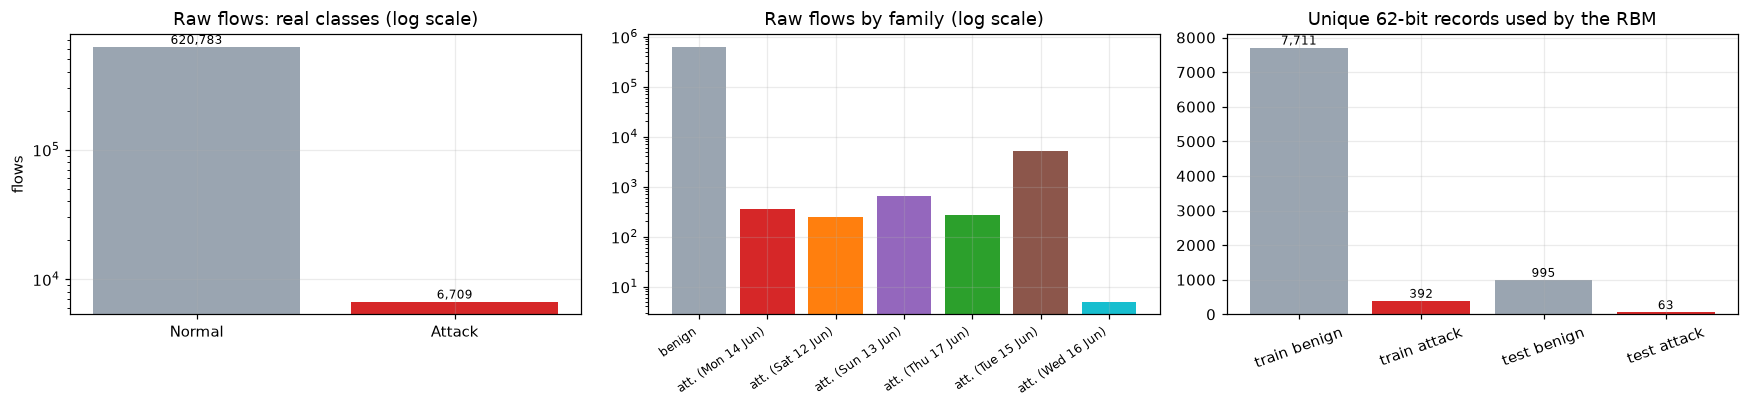

In [10]:
FAMILIES = ["benign"] + sorted(f for f in flows["family"].unique() if f != "benign")
FAM_COL = dict(zip(FAMILIES, ["#9aa5b1", "#d62728", "#ff7f0e", "#9467bd", "#2ca02c", "#8c564b", "#17becf", "#e377c2"]))

print("RAW FLOWS   shape:", flows.shape, "  (rows = distinct flows, columns below)")
print("feature columns used:", NUM_COLS + CAT_COLS + FLAG_COLS)
print("original label values:", flows["Label"].value_counts().to_dict())
display(pd.crosstab(flows["family"], flows["Label"], margins=True))
print("\nflow-level split used for the discretiser: train", d_tr.shape, "| test", d_te.shape)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
vc = flows["Label"].value_counts()
ax[0].bar(vc.index, vc.values, color=["#9aa5b1" if i == "Normal" else "#d62728" for i in vc.index]); ax[0].set_yscale("log")
ax[0].set_title("Raw flows: real classes (log scale)"); ax[0].set_ylabel("flows")
for i, v in enumerate(vc.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
fc = flows["family"].value_counts().reindex(FAMILIES)
ax[1].bar(range(len(fc)), fc.values, color=[FAM_COL[f] for f in fc.index]); ax[1].set_yscale("log")
ax[1].set_xticks(range(len(fc))); ax[1].set_xticklabels([f.replace("attack ", "att. ") for f in fc.index], fontsize=8, rotation=35, ha="right")
ax[1].set_title("Raw flows by family (log scale)")
fr = pd.DataFrame({"records": [int((ytr_u == 0).sum()), int((ytr_u == 1).sum()), int((yte_u == 0).sum()), int((yte_u == 1).sum())]},
                  index=["train benign", "train attack", "test benign", "test attack"])
ax[2].bar(fr.index, fr["records"], color=["#9aa5b1", "#d62728", "#9aa5b1", "#d62728"])
ax[2].set_title("Unique 62-bit records used by the RBM"); ax[2].tick_params(axis="x", labelrotation=20)
for i, v in enumerate(fr["records"]): ax[2].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

BINARISED RECORDS  train: (8103, 64)  test: (1058, 64)   (62 data bits + 2 target bits)
target-bit coding: 01 = benign, 10 = attack;  class counts train {'benign': 7711, 'attack': 392}  test {'benign': 995, 'attack': 63}

family counts of the unique records


,train,test
benign,7711,995
attack (Mon 14 Jun),77,15
attack (Sat 12 Jun),12,0
attack (Sun 13 Jun),164,28
attack (Thu 17 Jun),48,11
attack (Tue 15 Jun),91,9
attack (Wed 16 Jun),0,0



the 62 binary features (first 62 rows, ranked by the selection order):


,bit,MI with label (bits),P(bit=1 | benign),P(bit=1 | attack)
0,direction=L2R,0.035,0.858,0.102
1,totalSourceBytes>7292,0.023,0.297,0.222
2,totalDestinationPackets>142.5,0.022,0.258,0.138
3,totalDestinationBytes>1.604e+05,0.019,0.266,0.105
4,totalDestinationBytes>1.188e+05,0.017,0.351,0.153
...,...,...,...,...
57,appName=MSN,0.000,0.002,0.003
58,totalSourcePackets>2276,0.000,0.010,0.015
59,totalSourceBytes>32,0.000,0.995,1.000
60,appName=WebMediaVideo,0.000,0.002,0.000


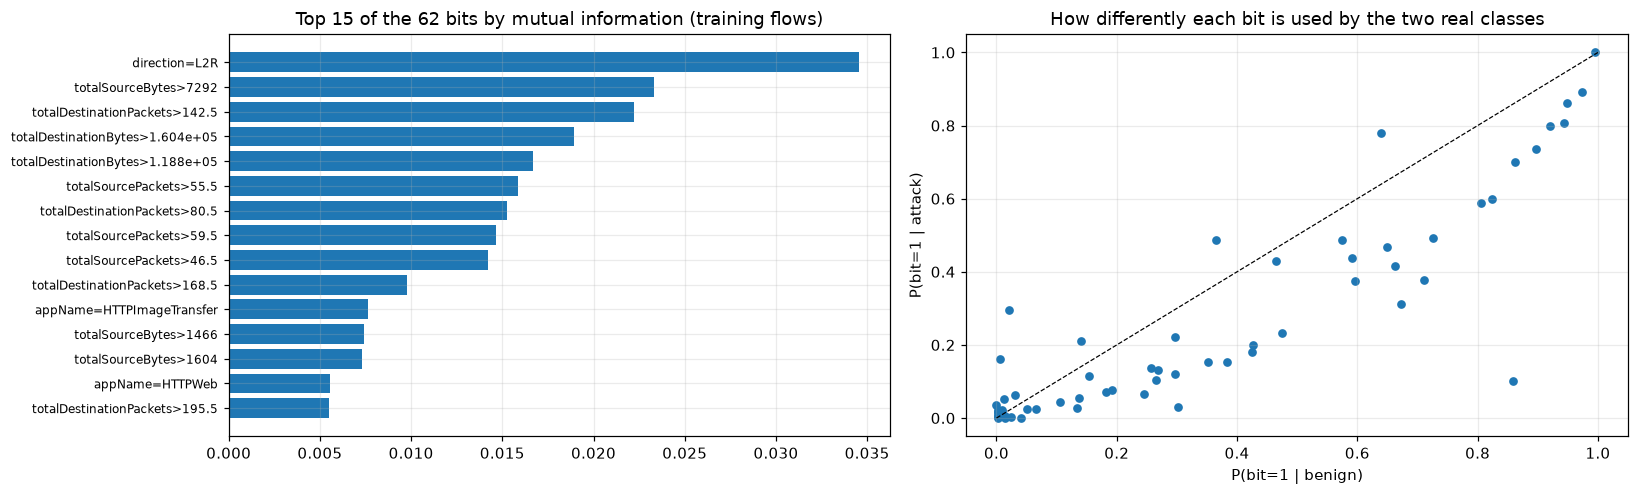

In [11]:
print("BINARISED RECORDS  train:", R_tr.shape, " test:", R_te.shape, "  (62 data bits + 2 target bits)")
print("target-bit coding: 01 = benign, 10 = attack;  class counts train", {"benign": int((ytr_u==0).sum()), "attack": int((ytr_u==1).sum())},
      " test", {"benign": int((yte_u==0).sum()), "attack": int((yte_u==1).sum())})
print("\nfamily counts of the unique records")
display(pd.DataFrame({"train": pd.Series(ftr_u).value_counts(), "test": pd.Series(fte_u).value_counts()}).reindex(FAMILIES).fillna(0).astype(int))

bits_df = pd.DataFrame({"bit": BIT_NAMES, "MI with label (bits)": mi_sel,
                        "P(bit=1 | benign)": Btr_u[ytr_u == 0].mean(0), "P(bit=1 | attack)": Btr_u[ytr_u == 1].mean(0)})
print("\nthe 62 binary features (first 62 rows, ranked by the selection order):")
display(bits_df.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
top = bits_df.sort_values("MI with label (bits)", ascending=False).head(15)[::-1]
ax[0].barh(top["bit"], top["MI with label (bits)"], color="#1f77b4"); ax[0].set_title("Top 15 of the 62 bits by mutual information (training flows)")
ax[0].tick_params(axis="y", labelsize=8)
ax[1].scatter(bits_df["P(bit=1 | benign)"], bits_df["P(bit=1 | attack)"], c="#1f77b4", s=22)
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].set_xlabel("P(bit=1 | benign)"); ax[1].set_ylabel("P(bit=1 | attack)")
ax[1].set_title("How differently each bit is used by the two real classes")
plt.tight_layout(); plt.show()

explained variance ratio of the two components: [0.362 0.094]


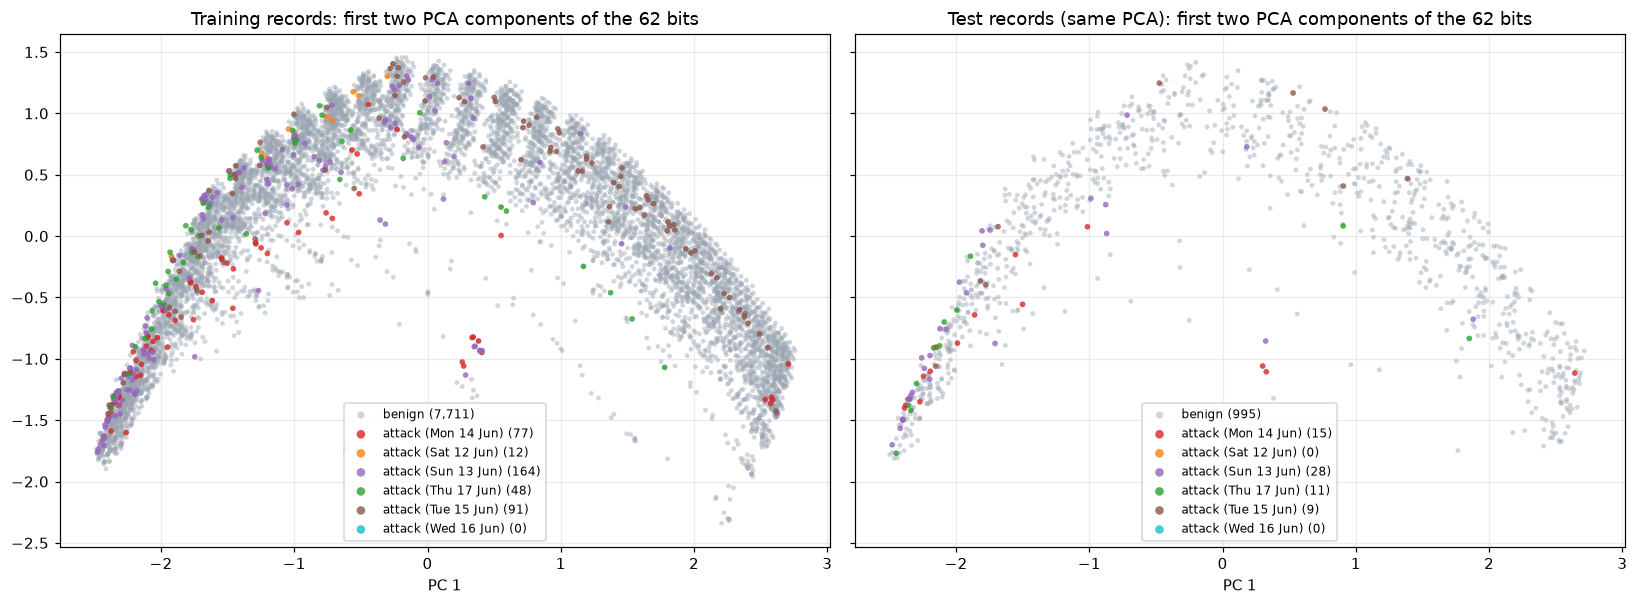

In [12]:
# Scatter 1: PCA of the 62 data bits, fitted on the TRAINING records only; every point is a real unique record coloured by family
pca_bits = PCA(n_components=2, random_state=SEED).fit(Btr_u.astype(float))
Ptr, Pte = pca_bits.transform(Btr_u.astype(float)), pca_bits.transform(Bte_u.astype(float))
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), sharex=True, sharey=True)
for a, P, fam, ttl in [(ax[0], Ptr, ftr_u, "Training records"), (ax[1], Pte, fte_u, "Test records (same PCA)")]:
    for f in FAMILIES:
        m = fam == f
        a.scatter(P[m, 0], P[m, 1], s=10 if f == "benign" else 14, alpha=0.45 if f == "benign" else 0.8, c=FAM_COL[f], label=f"{f} ({m.sum():,})",
                  zorder=1 if f == "benign" else 3, edgecolors="none")
    a.set_title(f"{ttl}: first two PCA components of the 62 bits"); a.set_xlabel("PC 1"); a.legend(fontsize=8, markerscale=1.5)
print("explained variance ratio of the two components:", pca_bits.explained_variance_ratio_.round(3))
plt.tight_layout(); plt.show()

explained variance ratio: [0.772 0.19 ]


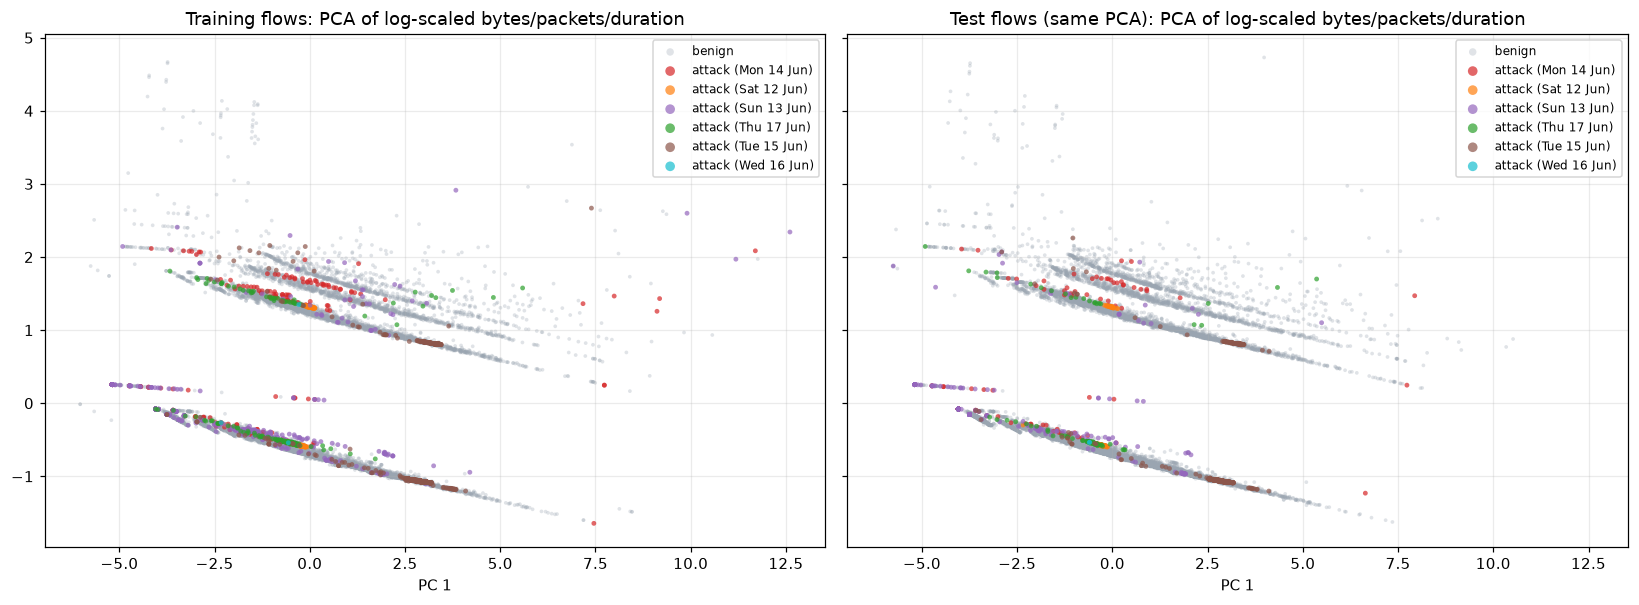

In [13]:
# Scatter 2: PCA of the raw numeric flow statistics (log1p, standardised) fitted on the TRAINING flows; all attack flows + 15,000 random benign flows are drawn
from sklearn.preprocessing import StandardScaler
Zt = np.log1p(d_tr[NUM_COLS].clip(lower=0).values.astype(float)); Ze = np.log1p(d_te[NUM_COLS].clip(lower=0).values.astype(float))
sc = StandardScaler().fit(Zt); pca_raw = PCA(n_components=2, random_state=SEED).fit(sc.transform(Zt))
Qt, Qe = pca_raw.transform(sc.transform(Zt)), pca_raw.transform(sc.transform(Ze))
srng = np.random.default_rng(SEED)
def draw_idx(fam):
    ben = np.where(fam == "benign")[0]; ben = srng.choice(ben, min(15000, len(ben)), replace=False)
    return np.r_[ben, np.where(fam != "benign")[0]]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), sharex=True, sharey=True)
for a, Q, fam, ttl in [(ax[0], Qt, d_tr["family"].values, "Training flows"), (ax[1], Qe, d_te["family"].values, "Test flows (same PCA)")]:
    ii = draw_idx(fam)
    for f in FAMILIES:
        m = fam[ii] == f
        a.scatter(Q[ii][m, 0], Q[ii][m, 1], s=6 if f == "benign" else 10, alpha=0.3 if f == "benign" else 0.7, c=FAM_COL[f], label=f, zorder=1 if f == "benign" else 3, edgecolors="none")
    a.set_title(f"{ttl}: PCA of log-scaled bytes/packets/duration"); a.set_xlabel("PC 1"); a.legend(fontsize=8, markerscale=2)
print("explained variance ratio:", pca_raw.explained_variance_ratio_.round(3))
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

NOT_APPLICABLE: the paper's model is a restricted Boltzmann machine whose negative phase is sampled from a D-Wave quantum annealer, i.e. an Ising/QUBO problem on a Chimera graph, not a gate-based circuit; in this notebook the annealer is replaced by a classical simulation of the same Ising Hamiltonian, so there is no quantum circuit to draw (qubit/depth/parameter counts do not exist; the RBM has 64 x 64 + 64 + 64 = 4,224 trainable parameters).

## 4. The RBM, contrastive divergence and the (simulated) annealer

**RBM.** 64 visible units $v$ (62 data bits + 2 target bits) and 64 hidden units $h$, energy $E(v,h)=-b^\top v-c^\top h-v^\top W h$ (Eq. 2 of the paper, written with $W$ as 64 x 64 visible-by-hidden).

**Gradient.** $\partial \ell/\partial W=\langle v h\rangle_{\text{data}}-\langle v h\rangle_{\text{model}}$ and likewise for $b$, $c$ (Eqs. 16-18). The *data term* is exact. The *model term* is where the two methods differ:
- **CD-1** (Algorithm 1): one reconstruction $V'=\sigma(b+HW^\top)$, $H'=\sigma(c+V'W)$ from the data.
- **Annealing** (Algorithm 2): $(V',H')$ are binary samples of the Boltzmann distribution of the RBM, produced by an annealer. The annealer is programmed with the Ising form of the RBM; the paper scales the Hamiltonian by $S$ so that $S\,kT\approx 1$.

**Ising form (Eqs. 20-23).** With spins $s=2x-1\in\{-1,+1\}$, the RBM energy equals $\sum_i h_i s_i+\sum_{i<j}J_{ij}s_is_j+\text{const}$ with $J=-W/4$ between a visible and a hidden spin, local fields $h_i=-(b_i/2+\sum_jW_{ij}/4)$ for visible and $h_j=-(c_j/2+\sum_iW_{ij}/4)$ for hidden spins (the minus signs are the D-Wave convention, which *minimises* the energy; the paper's Eqs. 21-23 list the positive magnitudes). The cell below builds exactly this Hamiltonian and **checks numerically** that it differs from the RBM energy by a state-independent constant.

**The simulated annealer** (`# CHOICE:`, replaces the D-Wave 2000Q): the 128 spins are initialised at random and swept with heat-bath updates whose inverse temperature rises geometrically from `BETA_START` to $S$; because the RBM is bipartite, all visible spins are updated at once given the hidden ones and vice versa (*annealed block Gibbs*). After `ANNEAL_SWEEPS` sweeps the state is one "read". With enough sweeps and $S=1$ this samples the model distribution exactly, which is the ideal that the hardware tries to approach; with few sweeps or $S\neq1$ it samples a colder or hotter, not fully equilibrated distribution, as an imperfect annealer does. Chimera embedding, chains and hardware noise are not simulated.

In [14]:
def sigmoid(x):
    return 0.5 * (1.0 + np.tanh(0.5 * x))

class RBM:
    """Bernoulli-Bernoulli RBM, E(v,h) = -b.v - c.h - v.W.h  (64 visible x 64 hidden)."""
    def __init__(self, n_vis=N_VIS, n_hid=N_HID, seed=0):
        r = np.random.default_rng(seed)
        self.W = r.normal(0.0, 0.01, (n_vis, n_hid))      # Algorithm 1: "small normally distributed random numbers"
        self.b = np.zeros(n_vis); self.c = np.zeros(n_hid)
    def hid_prob(self, V): return sigmoid(self.c + V @ self.W)             # Eq. 10
    def vis_prob(self, H): return sigmoid(self.b + H @ self.W.T)           # Eq. 11
    def energy(self, V, H): return -(V @ self.b) - (H @ self.c) - np.einsum("ni,ij,nj->n", V, self.W, H)
    def free_energy(self, V): return -(V @ self.b) - np.logaddexp(0.0, self.c + V @ self.W).sum(1)

def rbm_to_ising(rbm):
    """Eqs. 20-23 with the D-Wave sign convention. Returns (h_visible, h_hidden, J[visible, hidden])."""
    hv = -(rbm.b / 2 + rbm.W.sum(1) / 4)
    hh = -(rbm.c / 2 + rbm.W.sum(0) / 4)
    return hv, hh, -rbm.W / 4

def ising_energy(hv, hh, J, sv, sh):
    return sv @ hv + sh @ hh + np.einsum("ni,ij,nj->n", sv, J, sh)

def anneal_sample(rbm, n_reads, S, sweeps, rg, beta_start=BETA_START):
    """Simulated anneal of the Ising model of the RBM: n_reads independent reads, inverse temperature ramps geometrically to S."""
    betas = np.geomspace(beta_start, S, sweeps) if S > beta_start else np.full(sweeps, S)
    v = (rg.random((n_reads, rbm.W.shape[0])) < 0.5).astype(np.float64)
    for beta in betas:
        h = (rg.random((n_reads, rbm.W.shape[1])) < sigmoid(beta * (rbm.c + v @ rbm.W))).astype(np.float64)
        v = (rg.random(v.shape) < sigmoid(beta * (rbm.b + h @ rbm.W.T))).astype(np.float64)
    h = (rg.random((n_reads, rbm.W.shape[1])) < sigmoid(betas[-1] * (rbm.c + v @ rbm.W))).astype(np.float64)
    return v, h

def gibbs_generate(rbm, n, cycles, rg):
    """Paper's CD sampler: start from random 64-bit vectors and run `cycles` full Gibbs cycles; returns visible binary vectors."""
    v = (rg.random((n, rbm.W.shape[0])) < 0.5).astype(np.float64)
    for _ in range(cycles):
        h = (rg.random((n, rbm.W.shape[1])) < rbm.hid_prob(v)).astype(np.float64)
        v = (rg.random(v.shape) < rbm.vis_prob(h)).astype(np.float64)
    return v

# --- check the Ising mapping (Eqs. 21-23): E_RBM(v,h) - E_Ising(s) must be the same constant for every state ---
_r = np.random.default_rng(SEED); _t = RBM(seed=SEED); _t.W = _r.normal(0, 0.5, _t.W.shape); _t.b = _r.normal(0, 0.5, N_VIS); _t.c = _r.normal(0, 0.5, N_HID)
_v = (_r.random((200, N_VIS)) < .5).astype(float); _h = (_r.random((200, N_HID)) < .5).astype(float)
_hv, _hh, _J = rbm_to_ising(_t)
_diff = _t.energy(_v, _h) - ising_energy(_hv, _hh, _J, 2 * _v - 1, 2 * _h - 1)
print(f"E_RBM - E_Ising over 200 random states: mean {_diff.mean():.6f}, spread (max-min) {np.ptp(_diff):.2e}  -> constant offset: {np.ptp(_diff) < 1e-9}")
assert np.ptp(_diff) < 1e-9
print("Ising model: 128 spins,", N_VIS * N_HID, "couplings (complete bipartite graph).")

E_RBM - E_Ising over 200 random states: mean 5.865384, spread (max-min) 1.33e-13  -> constant offset: True
Ising model: 128 spins, 4096 couplings (complete bipartite graph).


In [15]:
def classify(rbm, X, readout="recon"):
    """Class codes for 62-bit inputs X: 0 benign, 1 attack, 2 indeterminate (target bits 00 or 11, counted as wrong).
    recon : apply the data bits with the target bits at 0, one up-down pass, threshold the two reconstructed target bits at 0.5 (paper).
    fe    : extra read-out, choose the target pattern (01 or 10) with the lower free energy."""
    V = np.hstack([X, np.zeros((len(X), N_LABEL))])
    if readout == "recon":
        t = rbm.vis_prob(rbm.hid_prob(V))[:, -2:] > 0.5
        pred = np.full(len(X), 2)
        pred[(~t[:, 0]) & t[:, 1]] = 0
        pred[t[:, 0] & (~t[:, 1])] = 1
        return pred
    V0, V1 = V.copy(), V.copy(); V0[:, -2:] = [0, 1]; V1[:, -2:] = [1, 0]
    return (rbm.free_energy(V1) < rbm.free_energy(V0)).astype(int)

def class_acc(pred, y):
    """(benign %, attack %, total %) exactly as the paper's A_benign, A_attack, A_tot."""
    return 100 * np.mean(pred[y == 0] == 0), 100 * np.mean(pred[y == 1] == 1), 100 * np.mean(pred == y)

def majority_vote(P):
    """P: (n_models, n_records) of codes 0/1/2; the code with most votes wins, ties give 'indeterminate' (2)."""
    cnt = np.stack([(P == k).sum(0) for k in (0, 1, 2)])
    win = cnt.argmax(0); tie = (cnt == cnt.max(0)).sum(0) > 1
    win[tie] = 2
    return win

def train_rbm(R, *, mode, epochs, seed, S=1.0, lr=LR, batch=BATCH, val=None):
    """Algorithm 1 (mode='cd1') or Algorithm 2 (mode='anneal'). Returns the RBM and a per-epoch history
    (reconstruction error on the training data and, if val=(X,y) is given, balanced accuracy on it)."""
    rbm, rg = RBM(seed=seed), np.random.default_rng(seed)
    hist = []
    for ep in range(epochs):
        perm = rg.permutation(len(R))
        for i in range(0, len(R), batch):
            V = R[perm[i:i + batch]]; m = len(V)
            H = rbm.hid_prob(V)                                         # data term, exact
            if mode == "cd1":
                V1 = rbm.vis_prob(H); H1 = rbm.hid_prob(V1)             # lines 7-8 of Algorithm 1
            else:
                V1, H1 = anneal_sample(rbm, m, S, ANNEAL_SWEEPS, rg)    # line 8 of Algorithm 2 (simulated annealer)
            rbm.W += lr * (V.T @ H - V1.T @ H1) / m
            rbm.b += lr * (V.sum(0) - V1.sum(0)) / m
            rbm.c += lr * (H.sum(0) - H1.sum(0)) / m
        rec = float(np.mean((R - rbm.vis_prob(rbm.hid_prob(R))) ** 2))
        rowh = {"epoch": ep + 1, "recon_mse": rec}
        if val is not None:
            pa = class_acc(classify(rbm, val[0]), val[1]); rowh["val_bal_acc"] = 0.5 * (pa[0] + pa[1])
        hist.append(rowh)
    return rbm, pd.DataFrame(hist)

### Cross-check of the simulated annealer

Before using the sampler for training, a check on a small RBM trained for a few epochs: the table lists the mean RBM energy of the reads of (i) a long block-Gibbs chain at inverse temperature 1 (the target distribution when $S\,kT=1$; 300 cycles from random starts), (ii) the own annealer for three values of $S$ and three anneal lengths, and (iii) the same Ising model handed to D-Wave's own classical `SimulatedAnnealingSampler` (from `dwave-samplers`, via `dimod`). Expected: the own annealer at $S=1$ and the `dwave-samplers` annealer give nearly the same energy (the implementation is sound); a short anneal sits somewhat *above* the long-chain energy (it is not fully equilibrated, like an imperfect annealer); $S<1$ is much too hot (high energy) and $S>1$ too cold (low energy).

In [16]:
_rb, _ = train_rbm(R_tr[:3000], mode="cd1", epochs=10, seed=SEED)
_rg = np.random.default_rng(SEED)
def _mean_energy(v, h): e = _rb.energy(v, h); return e.mean(), e.std()
rows = []
# exact reference: long block-Gibbs chains at beta = 1 (burn-in 300 cycles)
v = (_rg.random((400, N_VIS)) < .5).astype(float)
for _ in range(300):
    h = (_rg.random((400, N_HID)) < _rb.hid_prob(v)).astype(float); v = (_rg.random(v.shape) < _rb.vis_prob(h)).astype(float)
h = (_rg.random((400, N_HID)) < _rb.hid_prob(v)).astype(float)
rows.append(("long Gibbs chain, beta=1 (reference)", *_mean_energy(v, h)))
for S_ in (0.5, 1.0, 2.0):
    for sw in (5, ANNEAL_SWEEPS, 100):
        v, h = anneal_sample(_rb, 400, S_, sw, _rg); rows.append((f"own annealer S={S_}, {sw} sweeps", *_mean_energy(v, h)))
try:
    import dimod
    from dwave.samplers import SimulatedAnnealingSampler
    hv, hh, J = rbm_to_ising(_rb)
    r_, c_ = np.meshgrid(np.arange(N_VIS), np.arange(N_VIS, N_VIS + N_HID), indexing="ij")
    bqm = dimod.BinaryQuadraticModel.from_numpy_vectors(np.r_[hv, hh], (r_.ravel(), c_.ravel(), J.ravel()), 0.0, "SPIN")
    for sw in (ANNEAL_SWEEPS, 100):
        ss = SimulatedAnnealingSampler().sample(bqm, num_reads=200, num_sweeps=sw, beta_range=(BETA_START, 1.0), seed=SEED)
        s = ss.record.sample.astype(float); rows.append((f"dwave-samplers SA, {sw} sweeps (beta to 1)", *_mean_energy((s[:, :N_VIS] + 1) / 2, (s[:, N_VIS:] + 1) / 2)))
except Exception as e:
    print("dwave-samplers cross-check skipped:", e)
display(pd.DataFrame(rows, columns=["sampler", "mean RBM energy", "std"]).round(2))

,sampler,mean RBM energy,std
0,"long Gibbs chain, beta=1 (reference)",-67.06,7.69
1,"own annealer S=0.5, 5 sweeps",-12.64,11.29
2,"own annealer S=0.5, 20 sweeps",-16.62,11.43
3,"own annealer S=0.5, 100 sweeps",-18.24,10.67
4,"own annealer S=1.0, 5 sweeps",-55.15,11.25
5,"own annealer S=1.0, 20 sweeps",-54.16,9.44
6,"own annealer S=1.0, 100 sweeps",-56.09,9.72
7,"own annealer S=2.0, 5 sweeps",-76.18,7.48
8,"own annealer S=2.0, 20 sweeps",-74.61,8.04
9,"own annealer S=2.0, 100 sweeps",-82.67,5.72


### Choosing the scale $S$ (the paper's "manual search")

The paper treats $S$ as a hyper-parameter searched by hand and kept fixed during training. Here the search is automatic and uses **only the training data**: 10 % of the training records are held out as a validation set (never used to fit the discretiser, the RBMs or the classifiers), and each value of `S_GRID` trains an annealing RBM on a balanced sub-dataset made of the remaining training records for `S_SEARCH_EPOCHS` epochs. The value with the best balanced validation accuracy (mean of benign and attack accuracy) is used for all annealing-trained RBMs below.

In [17]:
# ---------- the five balanced sub-datasets A-E of Scheme 1 (built from the fitting records) ----------
def make_subdatasets(R, y, seed, k=5):
    """Scheme 1: split the benign records into k disjoint blocks of equal size; every block gets the attack records added so that the
    two classes are equally large (attack records are repeated at random when a block is larger than the attack set; the paper
    does this only for block E: 3,450 attack + 750 repeated records)."""
    g = np.random.default_rng(seed)
    ben, att = g.permutation(np.where(y == 0)[0]), np.where(y == 1)[0]
    blk = len(ben) // k
    blocks = [ben[i * blk:(i + 1) * blk] for i in range(k - 1)] + [ben[(k - 1) * blk:]]
    subs = []
    for b_ in blocks:
        if len(b_) >= len(att): a_ = np.r_[att, g.choice(att, len(b_) - len(att), replace=True)]
        else: a_ = g.choice(att, len(b_), replace=False)
        subs.append(R[np.r_[b_, a_]])
    return subs

subs = make_subdatasets(R_fit, y_fit, SEED)
print("sub-dataset sizes (A..E):", [len(s) for s in subs], "| each half benign, half attack (paper: 6,900 x4 and 8,400; here the attack records are repeated because the benign:attack ratio is larger)")

sub-dataset sizes (A..E): [2774, 2774, 2774, 2774, 2782] | each half benign, half attack (paper: 6,900 x4 and 8,400; here the attack records are repeated because the benign:attack ratio is larger)


,S,val balanced acc (%),final recon MSE
0,0.50,34.504,0.075
1,0.75,61.636,0.059
2,1.00,80.171,0.040
3,1.50,72.491,0.057
4,2.00,59.473,0.077


selected S = 1.0   (CD-1 reference on the same sub-dataset and epochs: validation balanced accuracy 79.21 %)   [157 s]


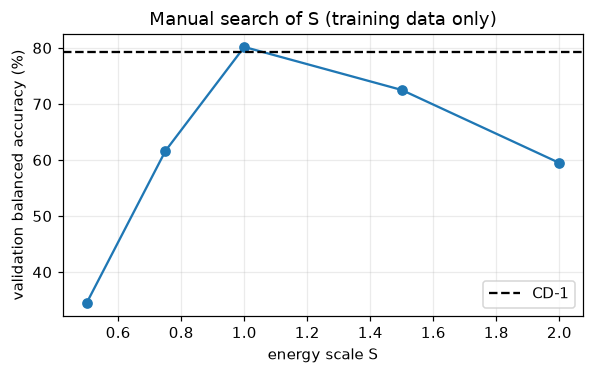

In [18]:
t0 = time.time(); srows = []
for S_ in S_GRID:
    rb_, h_ = train_rbm(subs[0], mode="anneal", epochs=S_SEARCH_EPOCHS, seed=SEED, S=S_, val=(R_val[:, :N_BITS], y_val))
    srows.append({"S": S_, "val balanced acc (%)": h_["val_bal_acc"].iloc[-1], "final recon MSE": h_["recon_mse"].iloc[-1]})
s_df = pd.DataFrame(srows); S_BEST = float(s_df.loc[s_df["val balanced acc (%)"].idxmax(), "S"])
cd_ref, h_cd_ref = train_rbm(subs[0], mode="cd1", epochs=S_SEARCH_EPOCHS, seed=SEED, val=(R_val[:, :N_BITS], y_val))
display(s_df.round(3))
print(f"selected S = {S_BEST}   (CD-1 reference on the same sub-dataset and epochs: validation balanced accuracy {h_cd_ref['val_bal_acc'].iloc[-1]:.2f} %)   [{time.time()-t0:.0f} s]")
fig, ax = plt.subplots(figsize=(5.5, 3.5)); ax.plot(s_df["S"], s_df["val balanced acc (%)"], "o-"); ax.axhline(h_cd_ref["val_bal_acc"].iloc[-1], color="k", ls="--", label="CD-1")
ax.set_xlabel("energy scale S"); ax.set_ylabel("validation balanced accuracy (%)"); ax.legend(); ax.set_title("Manual search of S (training data only)"); plt.tight_layout(); plt.show()

## 5. Classical baselines on the identical 62 bits

Before the RBM experiments, two ordinary classifiers are trained on exactly the same 62-bit training records and tested on the same test records, so that the RBM numbers can be read against something familiar. They use the imbalanced training set (benign records far outnumber attack records), like the paper's "imbal" rows.

,model,acc,acc_nat,P_att,P_ben,R_att,R_ben,F1_att,F1_ben,time (s)
0,logistic regression,78.169,96.692,0.986,0.698,0.571,0.992,0.724,0.820,0.133
1,random forest,86.307,98.015,0.995,0.787,0.730,0.996,0.842,0.879,2.941


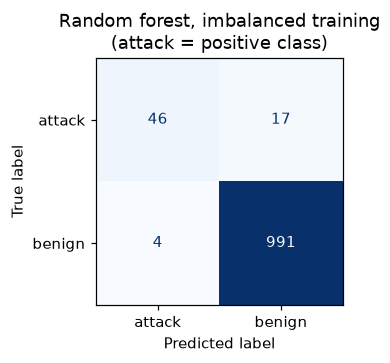

In [19]:
Xtr62, Xte62 = R_fit[:, :N_BITS], R_te[:, :N_BITS]
def prf(y, pred):
    """pred: class codes, 0 benign / 1 attack (2 = RBM 'indeterminate', a miss for both classes).
    acc_nat : accuracy on the natural (imbalanced) test set.  acc : balanced accuracy = accuracy on a test set with equally many benign and attack
    records (the paper's Table III numbers imply such a 500 + 500 test set, e.g. NN imbal: recalls 0.32 and 1.00 -> 66 %).  The precision / recall / F1
    columns are computed for that balanced test set (class-reweighted, so no sampling noise)."""
    y = np.asarray(y)
    r_att, r_ben = np.mean(pred[y == 1] == 1), np.mean(pred[y == 0] == 0)
    f_att, f_ben = np.mean(pred[y == 0] == 1), np.mean(pred[y == 1] == 0)          # benign called attack, attack called benign
    p_att = r_att / (r_att + f_att) if r_att + f_att > 0 else 0.0
    p_ben = r_ben / (r_ben + f_ben) if r_ben + f_ben > 0 else 0.0
    f1 = lambda p, r: 2 * p * r / (p + r) if p + r > 0 else 0.0
    return {"acc": 50 * (r_att + r_ben), "acc_nat": 100 * np.mean(pred == y), "P_att": p_att, "P_ben": p_ben, "R_att": r_att, "R_ben": r_ben,
            "F1_att": f1(p_att, r_att), "F1_ben": f1(p_ben, r_ben)}

base_rows = []
for name, clf in [("logistic regression", LogisticRegression(max_iter=2000, random_state=SEED)),
                  ("random forest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1))]:
    t0 = time.time(); clf.fit(Xtr62, y_fit); pr = clf.predict(Xte62)
    base_rows.append({"model": name, **prf(yte_u, pr), "time (s)": time.time() - t0})
display(pd.DataFrame(base_rows).round(3))
cm = confusion_matrix(yte_u, pr, labels=[1, 0])
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ConfusionMatrixDisplay(cm, display_labels=["attack", "benign"]).plot(ax=ax, colorbar=False, cmap="Blues"); ax.grid(False)
ax.set_title("Random forest, imbalanced training\n(attack = positive class)"); plt.tight_layout(); plt.show()

## 6. Training the RBMs: CD-1 and annealing, imbalanced data, Scheme 1 and Scheme 2

One function runs the whole protocol for one seed (the data split is fixed; the seed changes the RBM initialisation, the order of the mini-batches, the sub-dataset blocks, the annealer's random numbers and the classifiers):

1. **Imbalanced RBM** (CD-1 and annealing) trained on all training records; accuracy on a random 500 + 500 test subset (paper: attack 42 %, benign 97 %) and on the whole test set.
2. **Scheme 1**: five balanced sub-datasets A-E; for each, one CD-1 RBM and one annealing RBM; per-subset accuracies, average, standard deviation and the **majority vote** (Table I).
3. **Scheme 2 / Table II**: each of the ten Scheme-1 RBMs generates `N_SYN_T2` synthetic records (10,000 in the paper, fewer in FAST_MODE; CD: 50 Gibbs cycles from a random 64-bit vector; annealing: one read per record); a new CD-1 RBM is trained on each synthetic data set and tested on the real test set.
4. **Scheme 2 / Table III**: the imbalanced RBMs generate synthetic records; those whose target bits read `10` (attack) are added to the real training records until the two classes are equal; six classifiers (RBM, NN, KNN, SVC, DT, NB) plus logistic regression and random forest are trained on the balanced data ("CD-bal" / "QA-bal") and on the imbalanced data ("imbal") and tested on the real test set.

In [20]:
g500 = np.random.default_rng(SEED)
i_ben = g500.choice(np.where(yte_u == 0)[0], min(BAL_TEST, int((yte_u == 0).sum())), replace=False)
i_att = g500.choice(np.where(yte_u == 1)[0], min(BAL_TEST, int((yte_u == 1).sum())), replace=False)
i500 = np.r_[i_ben, i_att]                                    # the "500 attack + 500 benign" test subset of the paper
print("balanced test subset:", len(i_ben), "benign +", len(i_att), "attack")

def make_clfs(seed):
    return {"NN": MLPClassifier(hidden_layer_sizes=(8, 8, 8), activation="relu", solver="adam", max_iter=300, random_state=seed),   # 62-8-8-8-2 as in the paper
            "KNN": KNeighborsClassifier(n_neighbors=3),
            "SVC": SVC(),
            "DT": DecisionTreeClassifier(max_depth=5, random_state=seed),
            "NB": GaussianNB(),
            "LR (extra)": LogisticRegression(max_iter=2000, random_state=seed),
            "RF (extra)": RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1)}

def synth_attack(rbm, kind, n_need, seed):
    """Synthetic attack records (62 bits) from an RBM: keep generated vectors whose two target bits read 10."""
    g = np.random.default_rng(seed + 777); got, tried = [], 0
    while sum(len(x) for x in got) < n_need and tried < N_GEN_MAX:
        n = 25000
        v = gibbs_generate(rbm, n, 50, g) if kind == "cd" else anneal_sample(rbm, n, S_BEST, ANNEAL_SWEEPS, g)[0]
        tried += n; got.append(v[(v[:, -2] == 1) & (v[:, -1] == 0)][:, :N_BITS])
    Z = np.vstack(got); frac = len(Z) / tried
    return (Z[:n_need] if len(Z) > n_need else Z), tried, frac

def run_seed(seed, keep_models=False):
    t0 = time.time(); out = {}
    subs_s = make_subdatasets(R_fit, y_fit, seed)
    val = (R_val[:, :N_BITS], y_val)
    # ---- 1. imbalanced RBMs
    rb_imb = {}
    rb_imb["cd"], h_icd = train_rbm(R_fit, mode="cd1", epochs=EPOCHS_CD, seed=seed)
    rb_imb["qa"], h_iqa = train_rbm(R_fit, mode="anneal", epochs=EPOCHS_QA, seed=seed, S=S_BEST)
    out["imb"] = {k: {"bal500": class_acc(classify(m, Xte62[i500]), yte_u[i500]), "full": class_acc(classify(m, Xte62), yte_u),
                      "full_fe": class_acc(classify(m, Xte62, "fe"), yte_u)} for k, m in rb_imb.items()}
    print(f"  seed {seed}: imbalanced RBMs trained ({time.time()-t0:.0f} s)", flush=True)
    # ---- 2. Scheme 1 (Table I)
    mods = {"cd": [], "qa": []}; hist = {}
    for i, s in enumerate(subs_s):
        for k, mode, ep in (("cd", "cd1", EPOCHS_CD), ("qa", "anneal", EPOCHS_QA)):
            m, h = train_rbm(s, mode=mode, epochs=ep, seed=seed + 10 * i, S=S_BEST, val=val if i == 0 else None)
            mods[k].append(m)
            if i == 0: hist[k] = h
    t1 = {}
    for k in ("cd", "qa"):
        P = np.stack([classify(m, Xte62) for m in mods[k]])
        t1[k] = {"per": np.array([class_acc(p, yte_u) for p in P]), "mv": class_acc(majority_vote(P), yte_u), "P": P,
                 "mv_fe": class_acc(majority_vote(np.stack([classify(m, Xte62, "fe") for m in mods[k]])), yte_u)}
    out["t1"] = t1
    print(f"  seed {seed}: Scheme 1 done ({time.time()-t0:.0f} s)", flush=True)
    # ---- 3. Table II: RBMs trained on synthetic data generated by each of the ten Scheme-1 RBMs
    g = np.random.default_rng(seed + 5); t2 = {"cd": [], "qa": []}
    for k in ("cd", "qa"):
        for i, m in enumerate(mods[k]):
            Vs = gibbs_generate(m, N_SYN_T2, 50, g) if k == "cd" else anneal_sample(m, N_SYN_T2, S_BEST, ANNEAL_SWEEPS, g)[0]
            r2, _ = train_rbm(Vs, mode="cd1", epochs=max(EPOCHS_CD // 2, 10), seed=seed + 100 + i)
            t2[k].append(class_acc(classify(r2, Xte62), yte_u))
    out["t2"] = {k: np.array(v) for k, v in t2.items()}
    print(f"  seed {seed}: Table II done ({time.time()-t0:.0f} s)", flush=True)
    # ---- 4. Table III: balanced vs imbalanced training sets
    n_att, n_ben = int(y_fit.sum()), int((y_fit == 0).sum()); need = n_ben - n_att
    t3 = []; synth = {}
    for tag, kind in (("CD-bal", "cd"), ("QA-bal", "qa")):
        Z, tried, frac = synth_attack(rb_imb[kind], kind, need, seed)
        synth[tag] = (Z, tried, frac)
        Xb = np.vstack([Xtr62, Z]); yb = np.r_[y_fit, np.ones(len(Z), int)]
        Rb = np.vstack([R_fit, np.hstack([Z, np.tile([1.0, 0.0], (len(Z), 1))])])
        rbm_b, _ = train_rbm(Rb, mode="cd1", epochs=EPOCHS_CD, seed=seed + 7)
        pr = classify(rbm_b, Xte62)
        t3.append({"model": "RBM", "data": tag, **prf(yte_u, pr)})
        for name, clf in make_clfs(seed).items():
            clf.fit(Xb, yb); t3.append({"model": name, "data": tag, **prf(yte_u, clf.predict(Xte62))})
    pr = classify(rb_imb["cd"], Xte62); t3.append({"model": "RBM", "data": "imbal", **prf(yte_u, pr)})
    for name, clf in make_clfs(seed).items():
        clf.fit(Xtr62, y_fit); t3.append({"model": name, "data": "imbal", **prf(yte_u, clf.predict(Xte62))})
    out["t3"] = pd.DataFrame(t3)
    out["synth_info"] = {k: (len(v[0]), v[1], v[2]) for k, v in synth.items()}
    print(f"  seed {seed}: Table III done ({time.time()-t0:.0f} s)", flush=True)
    out["hist"] = hist
    if keep_models: out["models"] = {"mods": mods, "rb_imb": rb_imb, "synth": synth, "h_imb": {"cd": h_icd, "qa": h_iqa}}
    return out

print("running", len(SEEDS), "seed(s); S =", S_BEST)
RESULTS = []
for i_s, sd in enumerate(SEEDS):
    RESULTS.append(run_seed(sd, keep_models=(i_s == 0)))
print("all runs finished")

balanced test subset: 500 benign + 63 attack
running 3 seed(s); S = 1.0


  seed 42: imbalanced RBMs trained (198 s)


  seed 42: Scheme 1 done (498 s)


  seed 42: Table II done (645 s)


  seed 42: Table III done (1048 s)


...

  seed 44: imbalanced RBMs trained (164 s)


  seed 44: Scheme 1 done (446 s)


  seed 44: Table II done (717 s)


  seed 44: Table III done (1167 s)


all runs finished


### Training curves

The reconstruction error of the training data and the balanced validation accuracy per epoch for the first sub-dataset (A), CD-1 against the annealing sampler.

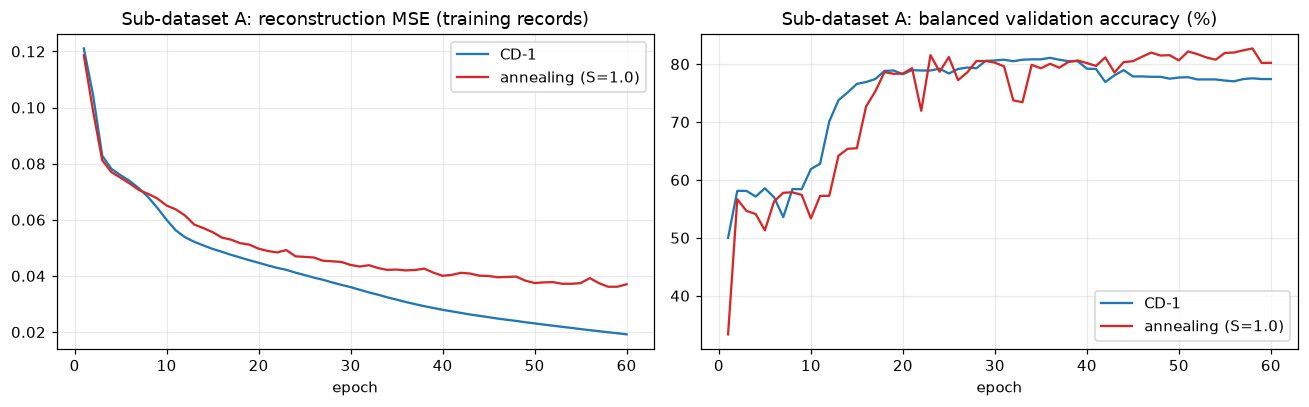

In [21]:
H = RESULTS[0]["hist"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, lab, col in (("cd", "CD-1", "#1f77b4"), ("qa", f"annealing (S={S_BEST})", "#d62728")):
    ax[0].plot(H[k]["epoch"], H[k]["recon_mse"], label=lab, color=col)
    ax[1].plot(H[k]["epoch"], H[k]["val_bal_acc"], label=lab, color=col)
ax[0].set_title("Sub-dataset A: reconstruction MSE (training records)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Sub-dataset A: balanced validation accuracy (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### Imbalanced RBM and Table I (Scheme 1)

Accuracies are in percent on the real test records (`benign` = $A_\text{benign}$, `attack` = $A_\text{attack}$, `total` = $A_\text{tot}$ of Eqs. 24-25). Records read out as `00` or `11` count as errors for both.

IMBALANCED training set (paper: CD-1 on 500+500: attack 42 %, benign 97 %)


,RBM,test,benign,attack,total
0,CD-1,500+500 test subset,97.13 +- 0.25,30.69 +- 5.40,89.70 +- 0.44
1,CD-1,whole test set,96.75 +- 0.17,30.69 +- 5.40,92.82 +- 0.35
2,CD-1,"whole test set, free-energy read-out (extra)",97.55 +- 0.21,50.26 +- 7.14,94.74 +- 0.24
3,annealing (S=1.0),500+500 test subset,98.67 +- 0.34,21.16 +- 1.98,89.99 +- 0.44
4,annealing (S=1.0),whole test set,98.66 +- 0.21,21.16 +- 1.98,94.05 +- 0.28
5,annealing (S=1.0),"whole test set, free-energy read-out (extra)",99.03 +- 0.09,31.22 +- 3.26,94.99 +- 0.20


TABLE I, Scheme 1 (paper: CD avg total 90.24, MV 95.68 | QA avg total 74.14, MV 80.04); QA here = simulated annealer


,dataset,CD benign,CD attack,CD total,QA benign,QA attack,QA total
0,A,84.62 +- 1.21,95.77 +- 2.70,85.29 +- 1.14,89.75 +- 1.58,95.24 +- 3.43,90.08 +- 1.28
1,B,84.52 +- 2.61,94.71 +- 3.26,85.13 +- 2.27,89.78 +- 3.16,92.06 +- 4.49,89.92 +- 2.71
2,C,84.96 +- 2.17,91.53 +- 5.40,85.35 +- 1.74,88.78 +- 1.57,96.30 +- 0.75,89.22 +- 1.44
3,D,84.72 +- 0.85,95.24 +- 1.30,85.35 +- 0.81,91.12 +- 0.99,91.53 +- 3.74,91.15 +- 0.72
4,E,85.53 +- 0.72,92.59 +- 4.55,85.95 +- 0.47,89.35 +- 0.90,96.83 +- 1.30,89.79 +- 0.77
5,Average over A-E,84.87 +- 0.55,93.97 +- 2.63,85.41 +- 0.37,89.76 +- 1.08,94.39 +- 0.91,90.03 +- 0.96
6,Std over A-E,1.60 +- 0.34,2.94 +- 0.98,1.37 +- 0.36,1.60 +- 0.48,3.64 +- 0.58,1.30 +- 0.46
7,Majority vote,85.59 +- 0.60,96.30 +- 1.98,86.23 +- 0.45,90.08 +- 0.95,95.77 +- 1.50,90.42 +- 0.83


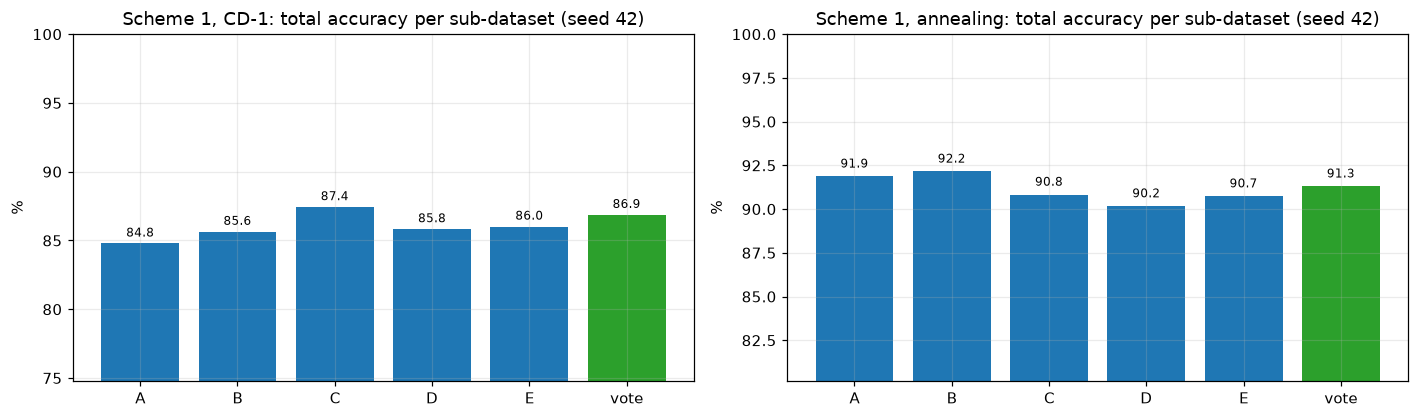

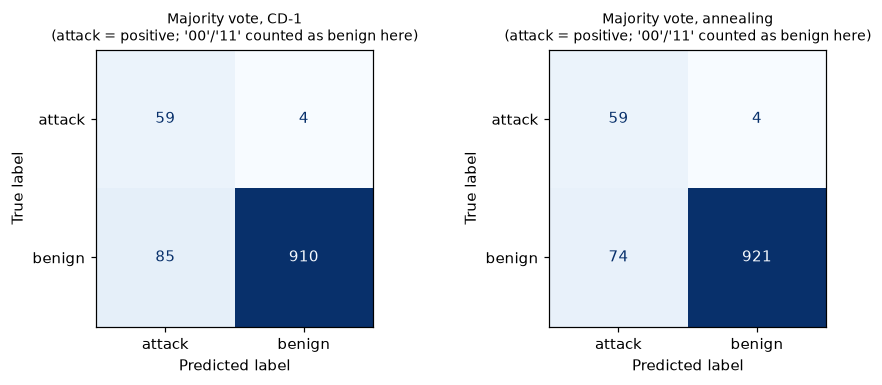

In [22]:
def ms(a):  # mean +- std over seeds
    a = np.asarray(a, float); return f"{a.mean():.2f} +- {a.std():.2f}" if len(a) > 1 else f"{a.mean():.2f}"
imb_rows = []
for k, lab in (("cd", "CD-1"), ("qa", f"annealing (S={S_BEST})")):
    for key, nm in (("bal500", f"500+500 test subset"), ("full", "whole test set"), ("full_fe", "whole test set, free-energy read-out (extra)")):
        A = np.array([r["imb"][k][key] for r in RESULTS])
        imb_rows.append({"RBM": lab, "test": nm, "benign": ms(A[:, 0]), "attack": ms(A[:, 1]), "total": ms(A[:, 2])})
print("IMBALANCED training set (paper: CD-1 on 500+500: attack 42 %, benign 97 %)")
display(pd.DataFrame(imb_rows))

names = list("ABCDE")
t1_rows = []
for i, n in enumerate(names):
    row = {"dataset": n}
    for k in ("cd", "qa"):
        A = np.array([r["t1"][k]["per"][i] for r in RESULTS])        # (seeds, 3)
        row.update({f"{k.upper()} benign": ms(A[:, 0]), f"{k.upper()} attack": ms(A[:, 1]), f"{k.upper()} total": ms(A[:, 2])})
    t1_rows.append(row)
avg = {"dataset": "Average over A-E"}; sd_ = {"dataset": "Std over A-E"}; mv = {"dataset": "Majority vote"}
for k in ("cd", "qa"):
    P = np.array([r["t1"][k]["per"] for r in RESULTS])               # (seeds, 5, 3)
    for j, c in enumerate(("benign", "attack", "total")):
        avg[f"{k.upper()} {c}"] = ms(P[:, :, j].mean(1)); sd_[f"{k.upper()} {c}"] = ms(P[:, :, j].std(1))
        mv[f"{k.upper()} {c}"] = ms([r["t1"][k]["mv"][j] for r in RESULTS])
t1_df = pd.DataFrame(t1_rows + [avg, sd_, mv])
print("TABLE I, Scheme 1 (paper: CD avg total 90.24, MV 95.68 | QA avg total 74.14, MV 80.04); QA here = simulated annealer")
display(t1_df)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
r0 = RESULTS[0]["t1"]; x = np.arange(6)
for a, k, ttl in ((ax[0], "cd", "CD-1"), (ax[1], "qa", "annealing")):
    tot = list(r0[k]["per"][:, 2]) + [r0[k]["mv"][2]]
    a.bar(x, tot, color=["#1f77b4"] * 5 + ["#2ca02c"]); a.set_xticks(x); a.set_xticklabels(names + ["vote"])
    a.set_ylim(min(tot) - 10 if min(tot) > 15 else 0, 100); a.set_title(f"Scheme 1, {ttl}: total accuracy per sub-dataset (seed {SEEDS[0]})"); a.set_ylabel("%")
    for xi, v in zip(x, tot): a.text(xi, v + 0.5, f"{v:.1f}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.6))
for a, k, ttl in ((ax[0], "cd", "CD-1"), (ax[1], "qa", "annealing")):
    pv = r0[k]["P"]; mvp = majority_vote(pv); pred01 = (mvp == 1).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(yte_u, pred01, labels=[1, 0]), display_labels=["attack", "benign"]).plot(ax=a, colorbar=False, cmap="Blues"); a.grid(False)
    a.set_title(f"Majority vote, {ttl}\n(attack = positive; '00'/'11' counted as benign here)", fontsize=9)
plt.tight_layout(); plt.show()

### Table II (RBMs trained on synthetic data) and the quality of the synthetic records

Each of the ten Scheme-1 RBMs generated a synthetic data set; a fresh CD-1 RBM trained on it is tested on the real test set. The scatter plot compares the real training records with the synthetic ones generated by the imbalanced CD-1 RBM, in the PCA plane of the real training records.

TABLE II (paper averages: CD-generated 68.28 / 85.66 / 71.21, QA-generated 67.47 / 72.90 / 70.00 for benign / attack / total)


,synthetic data,model,benign,attack,total
0,generated by CD-1 RBM,A-CD,74.44 +- 4.87,65.08 +- 20.74,73.88 +- 3.86
1,generated by CD-1 RBM,B-CD,74.37 +- 1.15,62.43 +- 11.62,73.66 +- 0.89
2,generated by CD-1 RBM,C-CD,78.19 +- 0.67,67.20 +- 9.10,77.54 +- 0.98
3,generated by CD-1 RBM,D-CD,77.35 +- 5.02,66.67 +- 4.67,76.72 +- 4.46
4,generated by CD-1 RBM,E-CD,75.21 +- 5.18,77.25 +- 9.38,75.33 +- 4.55
5,generated by CD-1 RBM,Average,75.91 +- 2.48,67.72 +- 6.48,75.43 +- 1.97
6,generated by CD-1 RBM,Std,3.35 +- 0.79,10.12 +- 5.70,3.05 +- 0.79
7,generated by annealing RBM,A-QA,83.62 +- 3.81,92.06 +- 4.67,84.12 +- 3.73
8,generated by annealing RBM,B-QA,85.93 +- 1.15,89.95 +- 1.98,86.17 +- 1.12
9,generated by annealing RBM,C-QA,79.93 +- 3.10,95.77 +- 0.75,80.88 +- 2.94


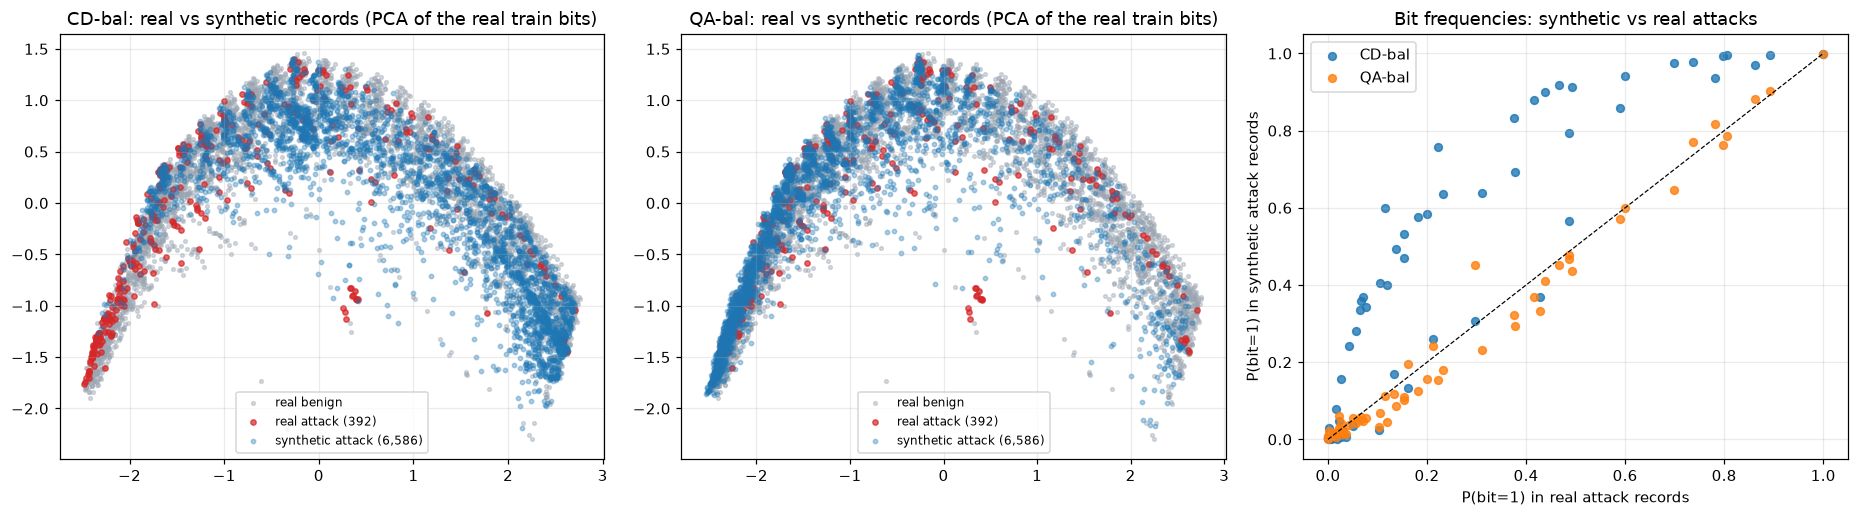

CD-bal: kept 6,586 synthetic attack records out of 175,000 draws (4.0% read out as attack); real attack records 353, benign 6,939
QA-bal: kept 6,586 synthetic attack records out of 375,000 draws (1.8% read out as attack); real attack records 353, benign 6,939


In [23]:
t2_rows = []
for k, lab in (("cd", "generated by CD-1 RBM"), ("qa", "generated by annealing RBM")):
    A = np.array([r["t2"][k] for r in RESULTS])                      # (seeds, 5, 3)
    for i, n in enumerate(names):
        t2_rows.append({"synthetic data": lab, "model": n + ("-CD" if k == "cd" else "-QA"), "benign": ms(A[:, i, 0]), "attack": ms(A[:, i, 1]), "total": ms(A[:, i, 2])})
    t2_rows.append({"synthetic data": lab, "model": "Average", "benign": ms(A[:, :, 0].mean(1)), "attack": ms(A[:, :, 1].mean(1)), "total": ms(A[:, :, 2].mean(1))})
    t2_rows.append({"synthetic data": lab, "model": "Std", "benign": ms(A[:, :, 0].std(1)), "attack": ms(A[:, :, 1].std(1)), "total": ms(A[:, :, 2].std(1))})
print("TABLE II (paper averages: CD-generated 68.28 / 85.66 / 71.21, QA-generated 67.47 / 72.90 / 70.00 for benign / attack / total)")
display(pd.DataFrame(t2_rows))

M = RESULTS[0]["models"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
real_att, real_ben = Btr_u[ytr_u == 1].astype(float), Btr_u[ytr_u == 0].astype(float)
for a, tag in ((ax[0], "CD-bal"), (ax[1], "QA-bal")):
    Z = M["synth"][tag][0]
    a.scatter(*pca_bits.transform(real_ben[::max(1, len(real_ben) // 3000)]).T, s=6, c=FAM_COL["benign"], alpha=0.4, label="real benign")
    a.scatter(*pca_bits.transform(real_att).T, s=12, c="#d62728", alpha=0.7, label=f"real attack ({len(real_att):,})")
    if len(Z): a.scatter(*pca_bits.transform(Z[::max(1, len(Z) // 3000)]).T, s=8, c="#1f77b4", alpha=0.35, label=f"synthetic attack ({len(Z):,})")
    a.set_title(f"{tag}: real vs synthetic records (PCA of the real train bits)"); a.legend(fontsize=8)
pa, pc = real_att.mean(0), None
for tag, col in (("CD-bal", "#1f77b4"), ("QA-bal", "#ff7f0e")):
    Z = M["synth"][tag][0]
    if len(Z): ax[2].scatter(pa, Z.mean(0), s=26, c=col, label=tag, alpha=0.8)
ax[2].plot([0, 1], [0, 1], "k--", lw=0.8); ax[2].set_xlabel("P(bit=1) in real attack records"); ax[2].set_ylabel("P(bit=1) in synthetic attack records")
ax[2].set_title("Bit frequencies: synthetic vs real attacks"); ax[2].legend()
plt.tight_layout(); plt.show()
for tag, (n_s, tried, frac) in RESULTS[0]["synth_info"].items():
    print(f"{tag}: kept {n_s:,} synthetic attack records out of {tried:,} draws ({frac:.1%} read out as attack); real attack records {int(y_fit.sum()):,}, benign {int((y_fit==0).sum()):,}")

### Table III (balanced training data and six classifiers)

`CD-bal` / `QA-bal`: real training records plus synthetic attack records from the CD-1 / annealing RBM until both classes have the same size; `imbal`: the original imbalanced training set. All models are tested on the same real test records. **Balanced evaluation.** The paper's Table III numbers are those of a *balanced* test set: for the neural network trained on imbalanced data it lists attack recall 0.32 and benign recall 1.00 and an accuracy of 66 %, which is exactly (0.32 + 1.00) / 2, and a benign precision of 0.60 = 1.00 / (1.00 + 0.68), as for 500 attack + 500 benign test records. The columns below are therefore computed for a balanced test set: `acc` is the balanced accuracy (mean of the two class recalls), precision and F1 re-weight the two classes to equal size (this is the expected value on a 500 + 500 sample without sampling noise), and `acc_nat` is the plain accuracy on the natural, benign-dominated test set. P, R and F1 are given for the attack class and the benign class.

TABLE III, measured here, balanced test set (paper: NN and KNN 93 % with balanced training data vs 66 / 70 % imbalanced; RBM 85 / 82 / 68 %; NB 65 % / 58 %)


acc  acc_nat  P_att  P_ben  R_att  R_ben  F1_att  F1_ben  acc std
model      data                                                                        
RBM        CD-bal  63.751   85.885  0.882  0.898  0.386  0.889   0.534   0.890    0.359
           QA-bal  75.709   87.870  0.944  0.835  0.619  0.895   0.733   0.862    6.028
           imbal   63.719   92.817  0.946  0.705  0.307  0.968   0.461   0.815    3.302
NN         CD-bal  90.991   94.707  0.948  0.882  0.868  0.952   0.905   0.914    3.570
           QA-bal  93.258   92.911  0.929  0.936  0.937  0.929   0.933   0.932    0.879
           imbal   86.535   97.511  0.987  0.798  0.741  0.990   0.841   0.882    6.485
KNN        CD-bal  85.439   96.849  0.978  0.782  0.725  0.984   0.833   0.871    0.532
           QA-bal  89.568   96.692  0.972  0.841  0.815  0.977   0.886   0.903    0.574
           imbal   83.082   97.543  0.993  0.749  0.667  0.995   0.798   0.855    0.000
SVC        CD-bal  88.603   93.478  0.934  0.848  0.831  0.941   0.879   0.892    0.989
           QA-bal  94.985   91.966  0.921  0.983  0.984  0.916   0.952   0.948    0.087
           imbal   78.471   97.259  0.996  0.700  0.571  0.998   0.726   0.823    0.000
DT         CD-bal  88.817   91.084  0.909  0.882  0.862  0.914   0.880   0.894    7.445
           QA-bal  94.335   91.210  0.914  0.977  0.979  0.908   0.945   0.941    0.389
           imbal   75.537   95.936  0.976  0.675  0.524  0.987   0.682   0.801    0.000
NB         CD-bal  69.974   89.666  0.861  0.638  0.476  0.923   0.613   0.755    1.831
           QA-bal  84.932   88.437  0.880  0.824  0.810  0.889   0.843   0.855    0.190
           imbal   77.749   59.546  0.696  0.973  0.984  0.571   0.816   0.720    0.000
LR (extra) CD-bal  89.792   93.384  0.933  0.869  0.857  0.939   0.893   0.902    3.106
           QA-bal  95.136   92.250  0.924  0.983  0.984  0.919   0.953   0.950    0.133
           imbal   78.169   96.692  0.986  0.698  0.571  0.992   0.724   0.820    0.000
RF (extra) CD-bal  90.305   95.747  0.960  0.859  0.841  0.965   0.897   0.909    1.552
           QA-bal  93.000   93.825  0.938  0.922  0.921  0.939   0.929   0.931    0.672
           imbal   85.249   97.889  0.994  0.774  0.709  0.996   0.827   0.871    1.790

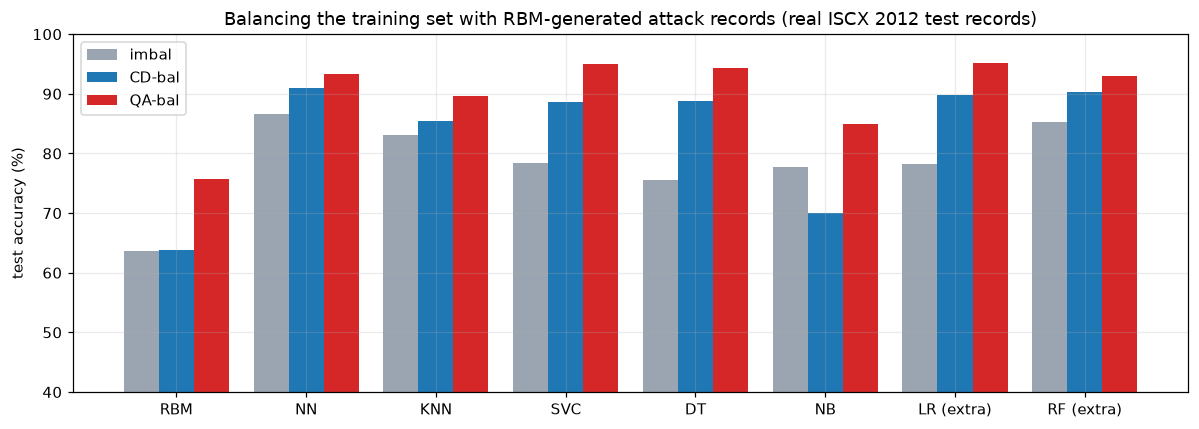

In [24]:
T3 = pd.concat([r["t3"].assign(seed=i) for i, r in enumerate(RESULTS)])
agg = T3.groupby(["model", "data"], sort=False)[["acc", "acc_nat", "P_att", "P_ben", "R_att", "R_ben", "F1_att", "F1_ben"]].mean()
agg_sd = T3.groupby(["model", "data"], sort=False)["acc"].std().fillna(0)
t3_show = agg.copy(); t3_show["acc std"] = agg_sd
order = ["RBM", "NN", "KNN", "SVC", "DT", "NB", "LR (extra)", "RF (extra)"]
t3_show = t3_show.reset_index(); t3_show["m"] = t3_show["model"].map({k: i for i, k in enumerate(order)}); t3_show["d"] = t3_show["data"].map({"CD-bal": 0, "QA-bal": 1, "imbal": 2})
t3_show = t3_show.sort_values(["m", "d"]).drop(columns=["m", "d"]).set_index(["model", "data"])
print("TABLE III, measured here, balanced test set (paper: NN and KNN 93 % with balanced training data vs 66 / 70 % imbalanced; RBM 85 / 82 / 68 %; NB 65 % / 58 %)")
display(t3_show.round(3))

fig, ax = plt.subplots(figsize=(11, 4)); w = 0.27
piv = agg["acc"].unstack("data").reindex(order)
for j, (d_, col) in enumerate((("imbal", "#9aa5b1"), ("CD-bal", "#1f77b4"), ("QA-bal", "#d62728"))):
    ax.bar(np.arange(len(order)) + (j - 1) * w, piv[d_].values, w, label=d_, color=col)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order); ax.set_ylabel("test accuracy (%)"); ax.set_ylim(40, 100); ax.legend()
ax.set_title("Balancing the training set with RBM-generated attack records (real ISCX 2012 test records)"); plt.tight_layout(); plt.show()

## 7. Side by side with the paper

Verdict rule: for every number the notebook reproduces the paper's claim when it is within **2 percentage points** (0.02 for F1/precision/recall); it is `exceeded` when it is more than that above the paper, `not reached` when more than that below. Qualitative claims get `reproduced` / `not reproduced`. Remember the two main differences: the data set is a re-derived 62-bit binarisation of six capture days (not the authors' Weka file), and "QA" is a **simulated annealer** (no D-Wave).

In [25]:
def verdict(paper, got, tol=2.0):
    if got is None or (isinstance(got, float) and np.isnan(got)): return "cannot be checked"
    return "reproduced" if abs(got - paper) <= tol else ("exceeded" if got > paper else "not reached")

def mean_over_seeds(f): return float(np.mean([f(r) for r in RESULTS]))
rows = []
def add(claim, paper, got, tol=2.0, unit=""):
    rows.append({"claim": claim, "paper": paper, "this notebook": round(got, 2) if got is not None else None, "gap": round(got - paper, 2) if got is not None else None,
                 "verdict": verdict(paper, got, tol)})
add("Imbalanced CD-1 RBM, attack accuracy (%), 500+500 test", 42, mean_over_seeds(lambda r: r["imb"]["cd"]["bal500"][1]))
add("Imbalanced CD-1 RBM, benign accuracy (%), 500+500 test", 97, mean_over_seeds(lambda r: r["imb"]["cd"]["bal500"][0]))
for j, c in enumerate(("benign", "attack", "total")):
    add(f"Table I CD-1, average {c} accuracy (%)", (90.51, 88.94, 90.24)[j], mean_over_seeds(lambda r: r["t1"]["cd"]["per"][:, j].mean()))
for j, c in enumerate(("benign", "attack", "total")):
    add(f"Table I CD-1, majority vote {c} accuracy (%)", (96.17, 93.25, 95.68)[j], mean_over_seeds(lambda r: r["t1"]["cd"]["mv"][j]))
for j, c in enumerate(("benign", "attack", "total")):
    add(f"Table I QA, average {c} accuracy (%)", (73.62, 71.18, 74.14)[j], mean_over_seeds(lambda r: r["t1"]["qa"]["per"][:, j].mean()))
for j, c in enumerate(("benign", "attack", "total")):
    add(f"Table I QA, majority vote {c} accuracy (%)", (74.46, 85.62, 80.04)[j], mean_over_seeds(lambda r: r["t1"]["qa"]["mv"][j]))
for j, c in enumerate(("benign", "attack", "total")):
    add(f"Table II CD-generated, average {c} accuracy (%)", (68.28, 85.66, 71.21)[j], mean_over_seeds(lambda r: r["t2"]["cd"][:, j].mean()))
for j, c in enumerate(("benign", "attack", "total")):
    add(f"Table II QA-generated, average {c} accuracy (%)", (67.47, 72.90, 70.00)[j], mean_over_seeds(lambda r: r["t2"]["qa"][:, j].mean()))
T3p = {("RBM", "CD-bal"): 85, ("RBM", "QA-bal"): 82, ("RBM", "imbal"): 68, ("NN", "CD-bal"): 93, ("NN", "QA-bal"): 93, ("NN", "imbal"): 66,
       ("KNN", "CD-bal"): 93, ("KNN", "QA-bal"): 93, ("KNN", "imbal"): 70, ("SVC", "CD-bal"): 83, ("SVC", "QA-bal"): 83, ("SVC", "imbal"): 63,
       ("DT", "CD-bal"): 86, ("DT", "QA-bal"): 86, ("DT", "imbal"): 61, ("NB", "CD-bal"): 65, ("NB", "QA-bal"): 65, ("NB", "imbal"): 58}
for (m_, d_), p_ in T3p.items():
    add(f"Table III {m_} {d_}, balanced accuracy (%)", p_, float(agg.loc[(m_, d_), "acc"]))
F1p = {("NN", "CD-bal"): 0.92, ("KNN", "CD-bal"): 0.92, ("RBM", "CD-bal"): 0.91, ("NN", "imbal"): 0.49, ("KNN", "imbal"): 0.57}
for (m_, d_), p_ in F1p.items():
    add(f"Table III {m_} {d_}, attack F1", p_, float(agg.loc[(m_, d_), "F1_att"]), tol=0.02)
cmp_df = pd.DataFrame(rows)
# qualitative claims
def qual(claim, ok): cmp_df.loc[len(cmp_df)] = {"claim": claim, "paper": "yes", "this notebook": "yes" if ok else "no", "gap": None, "verdict": "reproduced" if ok else "not reproduced"}
cd_avg = mean_over_seeds(lambda r: r["t1"]["cd"]["per"][:, 2].mean()); cd_mv = mean_over_seeds(lambda r: r["t1"]["cd"]["mv"][2])
qa_avg = mean_over_seeds(lambda r: r["t1"]["qa"]["per"][:, 2].mean()); qa_mv = mean_over_seeds(lambda r: r["t1"]["qa"]["mv"][2])
qual("Majority vote beats the average single RBM (CD-1)", cd_mv > cd_avg)
qual("Majority vote beats the average single RBM (annealing)", qa_mv > qa_avg)
qual("CD-1 total accuracy exceeds the annealing-trained RBM (majority vote)", cd_mv > qa_mv)
qual("Balanced sub-datasets raise the balanced accuracy (mean of benign and attack accuracy) of the CD-1 RBM over training on the imbalanced set", mean_over_seeds(lambda r: r["t1"]["cd"]["per"][:, :2].mean()) > mean_over_seeds(lambda r: np.mean(r["imb"]["cd"]["full"][:2])))
t2cd = mean_over_seeds(lambda r: r["t2"]["cd"][:, 2].mean()); t2qa = mean_over_seeds(lambda r: r["t2"]["qa"][:, 2].mean())
qual("Synthetic data from annealing-trained RBMs is about as useful as from CD-trained ones (Table II totals within 3 points)", abs(t2cd - t2qa) <= 3)
better = [bool(agg.loc[(m_, "CD-bal"), "acc"] > agg.loc[(m_, "imbal"), "acc"]) for m_ in ("RBM", "NN", "KNN", "SVC", "DT", "NB")]
qual(f"Every one of the six classifiers improves its balanced accuracy when the training set is balanced with CD-generated records ({sum(better)}/6 do)", all(better))
best2 = agg.loc[[(m_, "CD-bal") for m_ in ("RBM", "NN", "KNN", "SVC", "DT", "NB")], "acc"].sort_values(ascending=False)
qual("KNN and NN are the two best classifiers on the CD-balanced data", set(i[0] for i in best2.index[:2]) == {"NN", "KNN"})
pd.set_option("display.max_colwidth", 120); pd.set_option("display.max_rows", 200)
display(cmp_df)
counts = cmp_df["verdict"].value_counts()
print("\nVERDICT COUNTS:", counts.to_dict(), "| total claims", len(cmp_df))

,claim,paper,this notebook,gap,verdict
0,"Imbalanced CD-1 RBM, attack accuracy (%), 500+500 test",42.0,30.69,-11.31,not reached
1,"Imbalanced CD-1 RBM, benign accuracy (%), 500+500 test",97.0,97.13,0.13,reproduced
2,"Table I CD-1, average benign accuracy (%)",90.51,84.87,-5.64,not reached
3,"Table I CD-1, average attack accuracy (%)",88.94,93.97,5.03,exceeded
4,"Table I CD-1, average total accuracy (%)",90.24,85.41,-4.83,not reached
5,"Table I CD-1, majority vote benign accuracy (%)",96.17,85.59,-10.58,not reached
6,"Table I CD-1, majority vote attack accuracy (%)",93.25,96.3,3.05,exceeded
7,"Table I CD-1, majority vote total accuracy (%)",95.68,86.23,-9.45,not reached
8,"Table I QA, average benign accuracy (%)",73.62,89.76,16.14,exceeded
9,"Table I QA, average attack accuracy (%)",71.18,94.39,23.21,exceeded



VERDICT COUNTS: {'exceeded': 26, 'not reached': 14, 'reproduced': 6, 'not reproduced': 4} | total claims 50


In [26]:
# Where the classical baselines stand next to the RBMs (same inputs): balanced accuracy (acc), natural-test accuracy (acc_nat) and attack F1, mean over seeds
base = agg.reset_index()[["model", "data", "acc", "acc_nat", "F1_att"]].pivot(index="model", columns="data", values=["acc", "acc_nat", "F1_att"]).round(3)
display(base.reindex(order))
n_b, n_a = int((yte_u == 0).sum()), int((yte_u == 1).sum())
print(f"Sampling uncertainty of the test set: {n_b:,} benign and only {n_a:,} attack records, so a class accuracy near 90 % carries a binomial standard error of about "
      f"{100*np.sqrt(0.9*0.1/n_b):.1f} points (benign) and {100*np.sqrt(0.9*0.1/n_a):.1f} points (attack); gaps to the paper below about 5 points on attack metrics are not significant.")
print("Extra, free-energy read-out of the imbalanced RBMs on the whole test set (total accuracy %):",
      {k: round(float(np.mean([r['imb'][k]['full_fe'][2] for r in RESULTS])), 2) for k in ('cd', 'qa')},
      " vs paper-style reconstruction read-out:", {k: round(float(np.mean([r['imb'][k]['full'][2] for r in RESULTS])), 2) for k in ('cd', 'qa')})

acc                 acc_nat                 F1_att              
data        CD-bal  QA-bal   imbal  CD-bal  QA-bal   imbal CD-bal QA-bal  imbal
model                                                                          
RBM         63.751  75.709  63.719  85.885  87.870  92.817  0.534  0.733  0.461
NN          90.991  93.258  86.535  94.707  92.911  97.511  0.905  0.933  0.841
KNN         85.439  89.568  83.082  96.849  96.692  97.543  0.833  0.886  0.798
SVC         88.603  94.985  78.471  93.478  91.966  97.259  0.879  0.952  0.726
DT          88.817  94.335  75.537  91.084  91.210  95.936  0.880  0.945  0.682
NB          69.974  84.932  77.749  89.666  88.437  59.546  0.613  0.843  0.816
LR (extra)  89.792  95.136  78.169  93.384  92.250  96.692  0.893  0.953  0.724
RF (extra)  90.305  93.000  85.249  95.747  93.825  97.889  0.897  0.929  0.827

Sampling uncertainty of the test set: 995 benign and only 63 attack records, so a class accuracy near 90 % carries a binomial standard error of about 1.0 points (benign) and 3.8 points (attack); gaps to the paper below about 5 points on attack metrics are not significant.
Extra, free-energy read-out of the imbalanced RBMs on the whole test set (total accuracy %): {'cd': 94.74, 'qa': 94.99}  vs paper-style reconstruction read-out: {'cd': 92.82, 'qa': 94.05}


## 8. Reading the paper critically

- **What this reproduction can and cannot say about "quantum".** The authors present a proof of concept that a D-Wave 2000Q can supply the model term of the RBM gradient; they do not claim an advantage, and their annealing-trained RBM is clearly worse than CD-1 (80 % against 96 % after the vote). Here the *simulated* annealer, which is exactly the same algorithm without hardware imperfections, trains an RBM that is **not worse** than CD-1 (compare the two halves of Table I): the large gap in the paper is therefore not intrinsic to annealing-based training. It points to what the authors themselves suspect, the effective-temperature mismatch, chains of 16 qubits and noise of the real device. The scale search also behaves as the theory says: $S=1$ (sampling the model at $kT=1$) is selected, smaller values (too hot) and larger values (too cold) give clearly worse validation accuracy. None of this is evidence for or against quantum effects; it only shows that the *classical* part of the method is sound and sensitive to the sampling temperature.
- **The data set and its binarisation matter more than the sampler.** After a supervised discretisation to 62 bits only a few thousand distinct flow records remain (7,711 benign and 392 attack training records here, against 25,230 + 4,917 unique records in the paper), the attack share is 4.8 % instead of about 16 %, and the test set holds only 63 attack records, so attack accuracies carry a standard error of about 4 points. How many unique records exist, and how hard they are, depends on the authors' unpublished Weka pipeline; this is the main reason why absolute numbers differ from the paper's even where the method is identical (the cleaning rule of this repository, no ports/IPs/time stamps, also removes information that the paper may have used).
- **Metrics are easy to misread.** On the natural, benign-dominated test set a neural network that misses a quarter of the attacks still has 97.5 % accuracy (`acc_nat` in Table III). The paper's Table III numbers are balanced-test numbers (they follow from its recalls and precisions), but the text does not say so; Table I, in contrast, is on the natural test set (its total accuracy is the benign/attack accuracy weighted 7,230 : 1,467). When comparing methods always check which test distribution a number belongs to.
- **Leakage in the original protocol.** The paper discretises on the whole data set and takes unique records before splitting. Here the discretiser, the 62-bit selection and every other fitted transform see only training flows, and test records identical to a training record are removed. This is stricter than the paper and part of why numbers differ.
- **Synthetic attack records.** Adding RBM-generated attack records lifts the balanced accuracy of most classifiers (more with annealing-generated than with CD-generated records, see the `acc` column of Table III), but the paper does not compare against the obvious references (random oversampling, SMOTE, class weights) so the benefit of the RBM itself is not isolated; the exercises ask for this. Note also that a Gibbs chain of 50 cycles started from random bits does not sample the model distribution (the bit-frequency plot shows CD-generated attack records that are biased towards ones), which is a property of the paper's generator, whereas annealing reads follow the real attack bit frequencies much more closely here.
- **Sampling speed.** The advertised advantage ("10,000 samples almost instantly") concerns the hardware. On a CPU, vectorised block-Gibbs sampling of 25,000 chains of a 64 x 64 RBM takes a few seconds.
- **Statistical caveat.** The paper reports one run per cell; the only uncertainty given is the standard deviation over the five sub-datasets. Differences of a few points between CD and QA rows, or between classifiers, are within that noise (and within the noise of a 63-record attack test set here).

## 9. Exercises

1. **Vary the temperature.** Run the search over `S_GRID` again with a wider grid (0.1 to 8) and plot the training curves of the worst and the best value. Explain why a too large $S$ (a sampler that is too cold) hurts.
2. **Anneal longer.** Raise `ANNEAL_SWEEPS` from 20 to 200 at $S=1$. Does the annealing RBM approach CD-1? What does that say about the paper's 20 microsecond anneals?
3. **Persistent chains.** Replace CD-1 by persistent CD (keep the fantasy particles between mini-batches). Does the majority-vote accuracy of Table I change?
4. **Class-weighted baselines.** Add `class_weight="balanced"` logistic regression and random oversampling to Table III. How much of the gain of the RBM-generated records remains?
5. **Different bits.** Change `N_BITS` or `CUTS_PER_FEATURE`, or add the destination port as a categorical column. How many unique records are left, and how do the Table I numbers move?